<a href="https://colab.research.google.com/github/hongkangshsng/1109_337_-.zip/blob/main/%E9%9F%8C%E9%AB%94%E9%AB%94%E9%A9%97%E5%B7%A5%E7%A8%8B%E5%B8%AB%E6%8A%80%E8%A1%93%E5%B0%88%E6%A1%88%E6%8E%A2%E8%A8%8E_%E6%9C%89%E5%85%AD%E9%A1%8C_(Q1_%E8%87%B3_Q6%E5%AE%8C%E6%95%B4%E7%9B%AE%E9%8C%84%E8%88%87%E6%A8%A1%E6%93%AC%E7%89%88)_%E6%B4%AA%E9%8F%AE%E5%B1%95_%E4%BD%BF%E7%94%A8google_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 韌體驗證工程師技術專案探討（六題核心考古題全集）

> **作者**：洪鏮展 (Kang-Zhan Hong)  
> **對應技術簡報**：`Firmware_Verification_Technical_Briefing_韌體工程師技術簡報.pptx`（Slide 1 ~ Slide 8）  
> **使用說明**：本筆記本完全對應技術簡報的 6 大核心考題與章節標題。請點開左側 **「目錄 (Table of Contents)」** 面板，即可直接點擊跳轉至任一題目、關鍵技術 Title 與 Python 模擬區塊。

---

## 📑 技術簡報與筆記本全局目錄對照表 (Master Table of Contents)

| 題號 | 簡報章節標籤 (Slide Header) | 核心面試考題與關鍵技術 Title | 狀態 | 包含之關鍵技術子節與 Python 模擬 |
| :--- | :--- | :--- | :--- | :--- |
| **第 1 題** | `01 / SERIAL PROTOCOL` | **I2C / SMBus 的 CRC 從 Addr+R/W 開始算** | ✅ **已完成** | `1.1` I2C 雙線物理層、Master/Slave 與 4 大速率模式<br>`1.2` 原生 I2C vs. SMBus PEC (CRC-8) 4 步驟計算起點<br>`1.3` HackMD 參考文獻 10 張波形與硬體圖引用對照表<br>`1.4` **[Python 模擬]** SMBus PEC 位移暫存器追蹤與封包邊界圖<br>`1.5` **[Python 模擬]** 上拉電阻 Rise Time ($t_r$) 與 9-Clock 死鎖解鎖 |
| **第 2 題** | `02 / MEMORY ARCHITECTURE` | **RAM 與 ROM (Flash) 決定變數與程式碼歸屬** | ✅ **已完成** | `2.1` RAM (SRAM/DRAM) 與 ROM (PROM/EPROM/EEPROM/Flash) 本質差異<br>`2.2` 簡報四維度完整對照表（揮發性、讀寫壽命、Linker 區段、驗證重點）<br>`2.3` MCU 記憶體配置（`.text`、`.rodata`、`.data`、`.bss`、Stack、Heap）與 LMA/VMA 開機搬移<br>`2.4` 韌體驗證實務：Stack Overflow (Canary 水位監控)、Heap 碎片化與 Flash 磨損保護<br>`2.5` **[Python 模擬]** STM32 Linker Map 配置、`Reset_Handler` 搬移與 Stack Canary 溢位模擬 |
| **第 3 題** | `03 / C POINTERS` | **Call by Value 保安全；Call by Address 省空間** | ✅ **已完成** | `3.1` 觀念釐清：為什麼面試常問「Code/Call by Value vs. Address」？<br>`3.2` 簡報雙欄核心對照：Call by Value（傳值）vs. Call by Address（傳址 / 指標）<br>`3.3` iT 邦幫忙參考文獻程式碼逐行拆解：單層指標傳址與雙重指標 (`int **ppa`) 記憶體追蹤<br>`3.4` 嵌入式 ARM 架構 (AAPCS `R0~R3`) 大型 `struct` 傳遞瓶頸與 `const T *ptr` 唯讀防呆最佳實踐<br>`3.5` **[Python 模擬]** Stack Frame 位址追蹤、雙重指標狀態機與 Struct 傳參開銷視覺化 |
| **第 4 題** | `04 / REAL-TIME CONTROL` | **中斷 (Interrupt) 讓 CPU 即時回應事件並保存現場** | ✅ **已完成** | `4.1` 什麼是中斷？Interrupt vs. Polling（輪詢）效率對比與 iT 邦幫忙 STM32 實例解析<br>`4.2` 簡報四階段中斷生命週期：事件觸發 (IRQ) $\rightarrow$ 保存現場 (8 暫存器壓棧) $\rightarrow$ 執行 ISR $\rightarrow$ 還原返回<br>`4.3` 深入解讀 iT 邦幫忙留言區追問：`read_button_input()` 2-bit 移位邊緣消抖演算法<br>`4.4` 韌體面試兩大必考鐵律：**ISR 短小原則**（禁阻塞延遲/`printf`）與 **`volatile` 關鍵字**防編譯器快取最佳化<br>`4.5` **[Python 模擬]** ARM NVIC 自動壓棧、Polling vs. ISR 時間軸、2-bit 消抖狀態機與 `volatile` 模擬 |
| **第 5 題** | `05 / COMPILER & MEMORY` | **`const` 決定變數進 ROM (`.rodata`) 或 RAM** | ✅ **已完成** | `5.1` 編譯期唯讀保護與指標修飾 (`const T *p` vs. `T * const p`)<br>`5.2` 全域/static `const` 進 `.rodata`、區域 `const` 在 Stack 與 `const volatile` 硬體暫存器<br>`5.3` **[Python 模擬]** const 指標操作語意與 ROM / RAM 記憶體歸屬視覺化模擬 |
| **第 6 題** | `06 / CIRCUIT ANALYSIS` | **由電流反推節點電壓與 KCL 並聯等效電路分析** | ✅ **已完成** | `6.1` 歐姆定律與克希荷夫電流定律 (KCL) 節點電壓法<br>`6.2` **[Python 模擬]** SymPy KCL 符號公式推導、NumPy 電流-電壓響應曲線與無字型缺字無損電路原理圖<br>`6.3` 韌體驗證實務：高邊/低邊電流監控 (Telemetry) 與 NTC 溫度漂移非線性補償演算法 |

---

## 📄 技術簡報 PDF 線上預覽 (Technical Briefing Preview)

> 執行下方儲存格即可直接在筆記本中預覽對應的技術簡報 PDF 檔案。請確保您已將 PDF 檔案上傳至左側的檔案總管 (`/content/`) 中。

In [45]:
import base64
from IPython.display import display, HTML
import os

# 💡 請將下方的檔名替換為您實際上傳的 PDF 檔案名稱
pdf_file_path = "Firmware_Verification_Technical_Briefing_韌體工程師技術簡報.pdf"

if os.path.exists(pdf_file_path):
    with open(pdf_file_path, "rb") as f:
        base64_pdf = base64.b64encode(f.read()).decode('utf-8')

    # 使用 HTML iframe 與 base64 將 PDF 完美內嵌於 Colab 中
    pdf_display = f'<iframe src="data:application/pdf;base64,{base64_pdf}" width="100%" height="650" type="application/pdf" style="border: 1px solid #ccc; border-radius: 8px;"></iframe>'
    display(HTML(pdf_display))
else:
    print(f"❌ 找不到檔案：'{pdf_file_path}'")
    print("請確認您已經將 PDF 檔案上傳至 Colab，並且檔名完全相符。")

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


---

# 【第一題】01 / SERIAL PROTOCOL：I2C / SMBus 的 CRC 從哪邊開始計算？

> **對應簡報頁次**：Slide 2 (`01 / SERIAL PROTOCOL — I2C / SMBus 的 CRC 從 Addr+R/W 開始算`)  
> **本題參考文獻**：
> 1. Barry, [《I2C 通訊協定深度解析：從底層物理特性、通訊時序到 Bus 鎖死排除實戰指南》](https://hackmd.io/@ITTfbB0ERYiVmzZhsSs2uw/SJRm7iNRi) (HackMD 技術專欄)
> 2. NXP Semiconductors, [《UM10204: I2C-bus specification and user manual (Rev. 7.0)》](https://www.nxp.com/documents/user_manual/UM10204.pdf)
> 3. Infineon Technologies, [《PSOC Control C3 MCU: Implementing PMBus/SMBus Target & Controller (AN242922)》](https://www.infineon.com/assets/row/public/documents/non-assigned/42/infineon-an242922-psoc-control-c3-pmbus-smbus-target-controller-modustoolbox-applicationnotes-en.pdf)

## 1.1 I2C 基礎定義、Master/Slave 架構與 4 大速率模式 (Speed Modes)

### (1) 雙線式物理層與主從角色定義
* **雙線式架構**：I2C 協定使用 **2 條雙向開汲極 (Open-Drain) 線路**——一條是串列資料線（**SDA**, Serial Data），另一條是串列時鐘線（**SCL**, Serial Clock），兩條線皆須透過上拉電阻（$R_p$）接至正電源 $V_{CC}$。
* **多裝置定址**：匯流排上可掛載多個裝置，每個裝置具備唯一的 **7-bit**（扣除保留位址 `0x00~0x07` 與 `0x78~0x7F` 後實務可用 **112 個位址**）或 **10-bit** 位址。
* **Master 與 Slave 分工**：
  * **Master（主動發送 / 控制方）**：主動發起通訊（產生 `START` 與 `STOP` 條件）並產生 `SCL` 時脈訊號（包含主機發送 Master-Transmit 與主機接收 Master-Receive）。
  * **Slave（被動發送 / 目標方）**：被動等待 Master 點名訪問（位址匹配）後才會回覆 `ACK` 並收發資料（包含從機接收 Slave-Receive 與從機發送 Slave-Transmit）。

### (2) I2C 四種標準速率規格 (I2C Speed)
依據 [NXP UM10204 規範](https://www.nxp.com/documents/user_manual/UM10204.pdf) 與 [HackMD 參考文獻](https://hackmd.io/@ITTfbB0ERYiVmzZhsSs2uw/SJRm7iNRi)：

| 速率模式 (Speed Mode) | 最高速率上限 | 最大允許上升時間 ($t_r$) | 典型上拉電阻 ($R_p$) 建議值 | 典型硬體應用場景 |
| :--- | :--- | :--- | :--- | :--- |
| **1. 標準模式 (Standard-mode)** | **100 kbit/s** | $\le 1000\text{ ns}$ | $10\text{ k}\Omega$（高電容時改用 $4.7\text{ k}\Omega$） | EEPROM、RTC、溫濕度感測器 |
| **2. 快速模式 (Fast-mode)** | **400 kbit/s** | $\le 300\text{ ns}$ | $4.7\text{ k}\Omega \\sim 2.2\text{ k}\Omega$ | MEMS 感測器、OLED、PMIC、風扇監控 IC |
| **3. 快速模式 PLUS (Fast-mode Plus, Fm+)** | **1 Mbit/s** | $\le 120\text{ ns}$ | $\approx 1\text{ k}\Omega$（須確認晶片 $I_{OL}$ 灌電流能力） | 高速感測器匯流排、高頻率狀態擷取 |
| **4. 高速模式 (High-speed mode, Hs-mode)** | **3.4 Mbit/s** | $\le 40\\sim 80\text{ ns}$ | Master 內建主動電流源上拉 | 高頻寬顯示與高速控制通道 |

---

## 1.2 簡報核心考題：標準 I2C 無強制 CRC；SMBus PEC (CRC-8) 四步驟從 `Addr+R/W` 開始算

對照技術簡報 **Slide 2 (`01 / SERIAL PROTOCOL`)**，回答此題時先區分**原生 I2C**、**SMBus/PMBus PEC** 與**感測器自訂 CRC**：

1. **STEP 1 — `Addr + R/W`（起算點）**：
   * 在伺服器電源管理（PMBus / SMBus）中，**PEC (Packet Error Code)** 採用 **CRC-8**（生成多項式 $C(x) = x^8 + x^2 + x + 1$，Hex 為 **`0x07`**，初始值 `0x00`）。
   * **從 `START (S)` 後的第一個 7-bit 從機位址與讀寫位元 (`Addr + R/W`，共 8 bits) 就開始計入 CRC！**
2. **STEP 2 — `Command`（含 Repeated START 後的位址）**：
   * 接著納入暫存器位址或命令位元組（Command Byte）。若為讀取交易（如 `Read Byte/Word`），在 **`Repeated START (Sr)` 之後再次送出的 `Slave Address + R` 同樣必須納入計算**。
3. **STEP 3 — `Data Bytes`（資料位元組）**：
   * 依序累積所有寫入或讀出的資料位元組，**全程不含 `START`、`Repeated START`、`STOP` 及 `ACK/NACK` 位元**。
4. **STEP 4 — `附加 PEC`（末端比對）**：
   * 於最後一個 Data Byte 後附加 1-byte `CRC-8 (PEC)`；接收端將整筆交易連同 PEC 一起跑完 CRC-8 運算，**餘數為 `0x00`** 即代表資料無誤。
   * *(補充對照)*：若是獨立感測器（如溫濕度計 **Sensirion SHT3x**，多項式 `0x31`、初值 `0xFF`），其 CRC 則**不涵蓋 Address 與 Command**，僅針對每 2 Bytes 感測資料計算。

---

## 1.3 HackMD 參考文獻技術重點與圖片引用對照

| 圖片編號 | 原文對應章節 | 技術重點與面試應用說明 | 參考文獻連結 / 原圖 |
| :--- | :--- | :--- | :--- |
| **圖 1.1** | `I2C Protocol` | **I2C 基本訊框時序**：標示 `S` (Start)、MSB first 資料位元、第 9 bit `ACK` 與 `P` (Stop)。 | [開啟 Imgur 原圖 (`D5751LB.png`)](https://i.imgur.com/D5751LB.png) |
| **圖 1.2** | `I2C Protocol -> ACK` | **邏輯分析儀實測 ACK / NAK**：展示主機寫入與讀取 `[0x38]`，讀取最後一個 Byte 時由 Master 發送 `NAK` 通知從機結束。 | [HackMD ACK 章節](https://hackmd.io/@ITTfbB0ERYiVmzZhsSs2uw/SJRm7iNRi#I2C-Protocol) |
| **圖 1.3** | `產生 NACK 的原因` | **NACK 異常排查**：包含位址無回應 (`[0x70]+NAK`)、Slave 忙碌中、資料無法識別、Buffer 已滿、匯流排雜訊過大。 | [HackMD NACK 章節](https://hackmd.io/@ITTfbB0ERYiVmzZhsSs2uw/SJRm7iNRi#%E7%94%A2%E7%94%9FNACK%E7%9A%84%E4%BA%94%E5%A4%A7%E5%8E%9F%E5%9B%A0) |
| **圖 1.4** | `NCT7904D / LTC3350 / ADE7880` | **多晶片讀寫時序與 Endianness**：`NCT7904D` 具 Bank 切換機制；`LTC3350`/`ADE7880` 多位元組為 Big-Endian，在 ARM (Little-Endian) MCU 上須做 Byte Swap。 | [開啟時序參數表原圖 (`HyszSCOKC.png`)](https://hackmd.io/_uploads/HyszSCOKC.png) |
| **圖 1.5** | `I2C 硬體 & Bus 鎖死` | **Open-Drain 電路與 9-Clock 解鎖**：說明為何不可用 Push-Pull，以及 SDA 被 Slave 卡死在 LOW 時如何切換 GPIO 打 9 個 SCL Clock + STOP 恢復。 | [HackMD 硬體章節](https://hackmd.io/@ITTfbB0ERYiVmzZhsSs2uw/SJRm7iNRi#I2C-%E7%A1%AC%E9%AB%94) |

![I2C 基本訊框時序圖](https://i.imgur.com/D5751LB.png)
![I2C 介面時序參數與波形圖](https://hackmd.io/_uploads/HyszSCOKC.png)

---

## 1.4 Python 模擬實戰 (一)：SMBus PEC (CRC-8) 逐步計算與封包邊界視覺化

【Q1 模擬一】SMBus PEC (CRC-8, Poly=0x07, Init=0x00) 逐步位移暫存器追蹤
交易情境：讀取從機 0x5A 暫存器 0x07 之 16-bit 數值 (Read Word Protocol)
--------------------------------------------------------------------------------------
步驟     | 封包欄位說明                                 | 輸入 Byte        | 初始 CRC   | XOR 後   | 8-bit 運算後 CRC
--------------------------------------------------------------------------------------
Byte 1 | Step 1: Addr+W (0x5A<<1 | 0 = 0xB4)    | 0xB4 (10110100) | 0x00     | 0xB4    | 0x05 (00000101)
Byte 2 | Step 2: Command (Reg = 0x07)           | 0x07 (00000111) | 0x05     | 0x02    | 0x0E (00001110)
Byte 3 | Step 2b: Sr + Addr+R (0x5A<<1 | 1 = 0xB5) | 0xB5 (10110101) | 0x0E     | 0xBB    | 0x28 (00101000)
Byte 4 | Step 3a: Data Low (0x3A)               | 0x3A (00111010) | 0x28     | 0x12    | 0x7E (01111110)
Byte 5 | Step 3b: Data High (0x0C)              | 0x0C (00001100) | 0x7E     | 0x72    | 0x59 (01011001)
---------------------------------------------------------------------------------

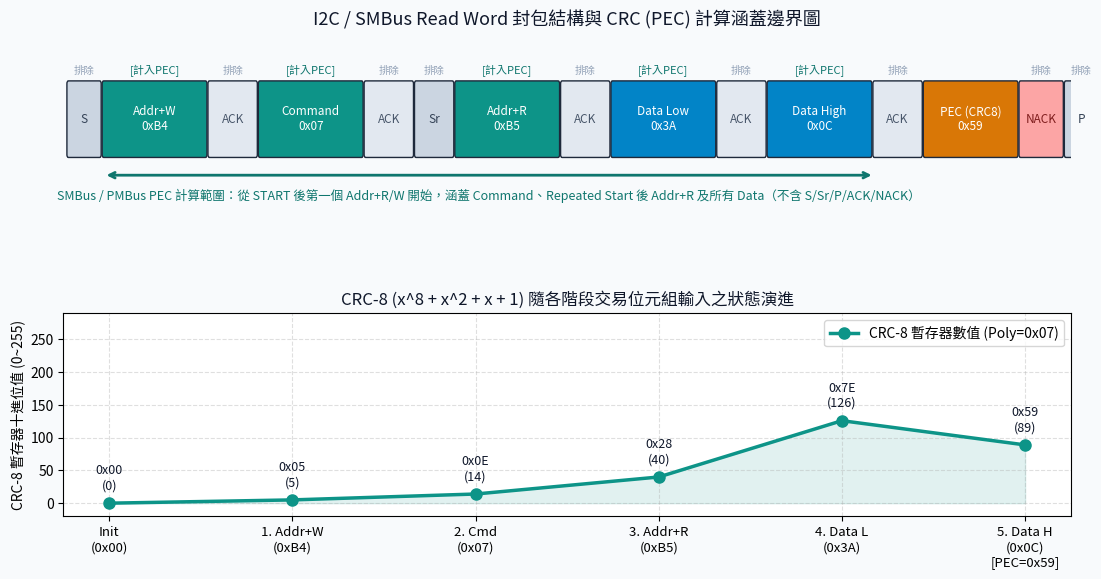

In [46]:
# 【第一題模擬 1.4】SMBus PEC (CRC-8, Poly=0x07) 逐步位移暫存器追蹤與封包計算邊界圖
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import urllib.request
import os
import matplotlib.font_manager as fm

# 自動下載並設定繁體中文字型，解決亂碼問題
font_path = "NotoSansCJKtc-Regular.otf"
if not os.path.exists(font_path):
    font_url = "https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf"
    urllib.request.urlretrieve(font_url, font_path)
fm.fontManager.addfont(font_path)
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK TC', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

def calc_crc8(data_bytes, poly=0x07, init=0x00):
    crc = init
    history = []
    for idx, b in enumerate(data_bytes):
        crc_in = crc
        crc ^= b
        after_xor = crc
        for _ in range(8):
            if crc & 0x80:
                crc = ((crc << 1) ^ poly) & 0xFF
            else:
                crc = (crc << 1) & 0xFF
        history.append((idx + 1, b, crc_in, after_xor, crc))
    return crc, history

tx_bytes = [0xB4, 0x07, 0xB5, 0x3A, 0x0C]
labels = [
    "Step 1: Addr+W (0x5A<<1 | 0 = 0xB4)",
    "Step 2: Command (Reg = 0x07)",
    "Step 2b: Sr + Addr+R (0x5A<<1 | 1 = 0xB5)",
    "Step 3a: Data Low (0x3A)",
    "Step 3b: Data High (0x0C)"
]

pec_val, hist = calc_crc8(tx_bytes, poly=0x07, init=0x00)
rx_rem, _ = calc_crc8(tx_bytes + [pec_val], poly=0x07, init=0x00)
sht_crc, _ = calc_crc8([0xBE, 0xEF], poly=0x31, init=0xFF)

print("=" * 86)
print("【Q1 模擬一】SMBus PEC (CRC-8, Poly=0x07, Init=0x00) 逐步位移暫存器追蹤")
print("交易情境：讀取從機 0x5A 暫存器 0x07 之 16-bit 數值 (Read Word Protocol)")
print("-" * 86)
print(f"{'步驟':<6} | {'封包欄位說明':<38} | {'輸入 Byte':<14} | {'初始 CRC':<8} | {'XOR 後':<7} | {'8-bit 運算後 CRC'}")
print("-" * 86)
for (step_i, b_val, c_in, c_xor, c_out), lbl in zip(hist, labels):
    print(f"Byte {step_i:<1} | {lbl:<38} | 0x{b_val:02X} ({b_val:08b}) | 0x{c_in:02X}     | 0x{c_xor:02X}    | 0x{c_out:02X} ({c_out:08b})")
print("-" * 86)
print(f"-> 最終計算出之 PEC (CRC-8) 校驗碼 = 0x{pec_val:02X}")
print(f"-> 接收端連同 PEC (共 6 Bytes) 重新計算之餘數 = 0x{rx_rem:02X} -> {'PASS (驗證通過！)' if rx_rem == 0 else 'FAIL'}")
print("=" * 86)
print("\n【對照組】感測器 Data-only CRC-8 (以 Sensirion SHT3x 為例：Poly=0x31, Init=0xFF)")
print(f"僅對 2-Byte 感測資料 [0xBE, 0xEF] 計算（不含 I2C Address 與 Command）-> CRC = 0x{sht_crc:02X} (符合原廠規格書 0x92)")

fig1 = plt.figure(figsize=(13, 6.2), facecolor='#F8FAFC')
gs = fig1.add_gridspec(2, 1, height_ratios=[1.15, 1.25], hspace=0.45)

ax0 = fig1.add_subplot(gs[0])
ax0.set_facecolor('#F8FAFC')
ax0.set_xlim(0, 100)
ax0.set_ylim(0, 10)
ax0.axis('off')
ax0.set_title("I2C / SMBus Read Word 封包結構與 CRC (PEC) 計算涵蓋邊界圖", fontsize=13, fontweight='bold', color='#0F172A', pad=10)

blocks = [
    ("S", 3.5, "#CBD5E1", "#334155", False),
    ("Addr+W\n0xB4", 10.5, "#0D9488", "white", True),
    ("ACK", 5.0, "#E2E8F0", "#475569", False),
    ("Command\n0x07", 10.5, "#0D9488", "white", True),
    ("ACK", 5.0, "#E2E8F0", "#475569", False),
    ("Sr", 4.0, "#CBD5E1", "#334155", False),
    ("Addr+R\n0xB5", 10.5, "#0D9488", "white", True),
    ("ACK", 5.0, "#E2E8F0", "#475569", False),
    ("Data Low\n0x3A", 10.5, "#0284C7", "white", True),
    ("ACK", 5.0, "#E2E8F0", "#475569", False),
    ("Data High\n0x0C", 10.5, "#0284C7", "white", True),
    ("ACK", 5.0, "#E2E8F0", "#475569", False),
    ("PEC (CRC8)\n0x59", 9.5, "#D97706", "white", False),
    ("NACK", 4.5, "#FCA5A5", "#7F1D1D", False),
    ("P", 3.5, "#CBD5E1", "#334155", False),
]

x_curr = 0.5
for text, w, bg, fg, in_pec in blocks:
    rect = patches.FancyBboxPatch((x_curr, 3.8), w - 0.4, 3.8, boxstyle="round,pad=0.15", facecolor=bg, edgecolor="#1E293B", linewidth=1.0)
    ax0.add_patch(rect)
    ax0.text(x_curr + (w - 0.4)/2, 5.7, text, ha='center', va='center', color=fg, fontsize=8.5, fontweight='bold')
    if in_pec:
        ax0.text(x_curr + (w - 0.4)/2, 8.3, "[計入PEC]", ha='center', va='center', color='#0F766E', fontsize=8, fontweight='bold')
    elif text in ["S", "Sr", "P", "ACK", "NACK"]:
        ax0.text(x_curr + (w - 0.4)/2, 8.3, "排除", ha='center', va='center', color='#94A3B8', fontsize=7.5)
    x_curr += w

ax0.annotate("", xy=(4.0, 2.7), xytext=(80.5, 2.7), arrowprops=dict(arrowstyle="<->", color="#0F766E", lw=2.0))
ax0.text(42.2, 1.6, "SMBus / PMBus PEC 計算範圍：從 START 後第一個 Addr+R/W 開始，涵蓋 Command、Repeated Start 後 Addr+R 及所有 Data（不含 S/Sr/P/ACK/NACK）",
         ha='center', va='center', color='#0F766E', fontsize=9, fontweight='bold')

ax1 = fig1.add_subplot(gs[1])
ax1.set_facecolor('#FFFFFF')
x_pos = np.arange(len(tx_bytes) + 1)
crc_trace = [0x00] + [h[4] for h in hist]
step_names = ["Init\n(0x00)", "1. Addr+W\n(0xB4)", "2. Cmd\n(0x07)", "3. Addr+R\n(0xB5)", "4. Data L\n(0x3A)", "5. Data H\n(0x0C)\n[PEC=0x59]"]

ax1.plot(x_pos, crc_trace, marker='o', markersize=8, linewidth=2.5, color='#0D9488', label='CRC-8 暫存器數值 (Poly=0x07)')
ax1.fill_between(x_pos, crc_trace, color='#0D9488', alpha=0.12)
for i, v in enumerate(crc_trace):
    ax1.annotate(f"0x{v:02X}\n({v})", (x_pos[i], v), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, fontweight='bold', color='#0F172A')

ax1.set_xticks(x_pos)
ax1.set_xticklabels(step_names, fontsize=9.5, fontweight='bold')
ax1.set_ylabel("CRC-8 暫存器十進位值 (0~255)", fontsize=10)
ax1.set_ylim(-20, 290)
ax1.set_title("CRC-8 (x^8 + x^2 + x + 1) 隨各階段交易位元組輸入之狀態演進", fontsize=12, fontweight='bold', color='#0F172A')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper right')
plt.show()


---

## 1.5 Python 模擬實戰 (二)：Open-Drain 上拉電阻 Rise Time ($t_r$) 與 9-Clock 匯流排死鎖恢復時序

【Q1 模擬二】I2C 開汲極 (Open-Drain) 上拉電阻 Rp 與上升時間 tr 分析 (假設匯流排電容 Cb = 200 pF)
公式依據：tr (30% VDD -> 70% VDD) = ln(0.7 / 0.3) * Rp * Cb = 0.8473 * Rp * Cb
規格上限：Standard-mode (100kHz) tr <= 1000 ns | Fast-mode (400kHz) tr <= 300 ns | Fast-mode Plus (1MHz) tr <= 120 ns
--------------------------------------------------------------------------------------
Rp = 10.0 kOhm | tau = 2000.0 ns | tr(30%~70%) = 1694.6 ns | 100kHz: FAIL | 400kHz: FAIL | 1MHz: FAIL
Rp =  4.7 kOhm | tau =  940.0 ns | tr(30%~70%) =  796.5 ns | 100kHz: PASS | 400kHz: FAIL | 1MHz: FAIL
Rp =  2.2 kOhm | tau =  440.0 ns | tr(30%~70%) =  372.8 ns | 100kHz: PASS | 400kHz: FAIL | 1MHz: FAIL
Rp =  1.0 kOhm | tau =  200.0 ns | tr(30%~70%) =  169.5 ns | 100kHz: PASS | 400kHz: PASS | 1MHz: FAIL

【Q1 模擬三】I2C Bus 鎖死 (SDA Stuck LOW) 與 9-Clock + STOP 軟體強制恢復時序驗證
故障成因：Master 讀取 Slave 途中發生非預期 Reset，Slave 正輸出 bit=0 而持續將 SDA 拉低，導致匯流排死鎖。
恢復結果：Master 切換 GPIO 輸出 9 個 SCL Clock 後，Slave 於第 9 個 Clock (NACK 階段) 釋放 SDA 回到 HIGH，Master 隨即發出 STOP 完成解鎖！


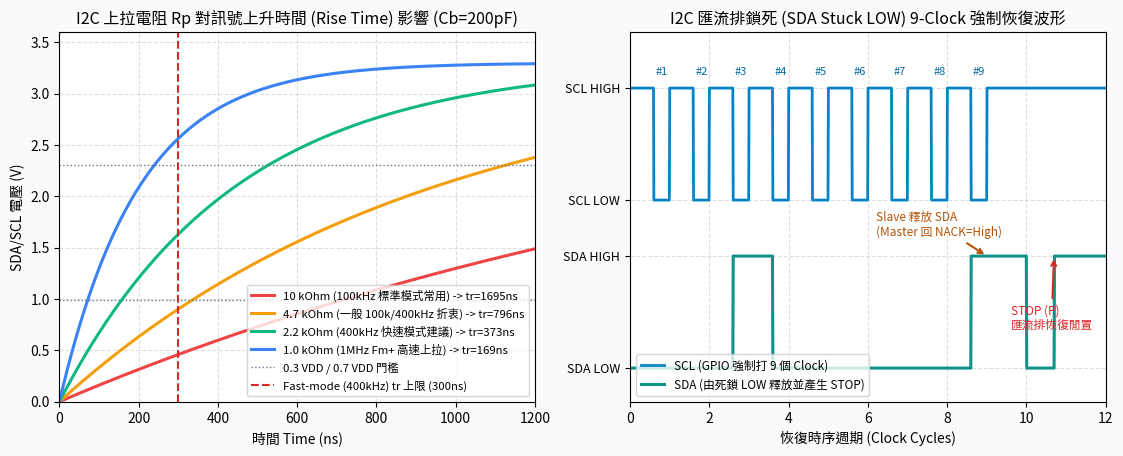

In [47]:
# 【第一題模擬 1.5】I2C Open-Drain 上拉電阻 Rise Time (tr) 與 9-Clock 匯流排死鎖恢復時序
t_ns = np.linspace(0, 1200, 600)
vdd = 3.3
c_bus_pf = 200.0
r_list = [
    (10.0, "10 kOhm (100kHz 標準模式常用)", "#EF4444"),
    (4.7,  "4.7 kOhm (一般 100k/400kHz 折衷)", "#F59E0B"),
    (2.2,  "2.2 kOhm (400kHz 快速模式建議)", "#10B981"),
    (1.0,  "1.0 kOhm (1MHz Fm+ 高速上拉)", "#3B82F6")
]

print("=" * 86)
print(f"【Q1 模擬二】I2C 開汲極 (Open-Drain) 上拉電阻 Rp 與上升時間 tr 分析 (假設匯流排電容 Cb = {c_bus_pf:.0f} pF)")
print("公式依據：tr (30% VDD -> 70% VDD) = ln(0.7 / 0.3) * Rp * Cb = 0.8473 * Rp * Cb")
print("規格上限：Standard-mode (100kHz) tr <= 1000 ns | Fast-mode (400kHz) tr <= 300 ns | Fast-mode Plus (1MHz) tr <= 120 ns")
print("-" * 86)
for r_kohm, desc, _ in r_list:
    tau_ns = r_kohm * c_bus_pf
    tr_ns = 0.84729786 * tau_ns
    pass_100k = "PASS" if tr_ns <= 1000 else "FAIL"
    pass_400k = "PASS" if tr_ns <= 300 else "FAIL"
    pass_1m   = "PASS" if tr_ns <= 120 else "FAIL"
    print(f"Rp = {r_kohm:>4.1f} kOhm | tau = {tau_ns:>6.1f} ns | tr(30%~70%) = {tr_ns:>6.1f} ns | 100kHz: {pass_100k:<4} | 400kHz: {pass_400k:<4} | 1MHz: {pass_1m:<4}")
print("=" * 86)
print("\n【Q1 模擬三】I2C Bus 鎖死 (SDA Stuck LOW) 與 9-Clock + STOP 軟體強制恢復時序驗證")
print("故障成因：Master 讀取 Slave 途中發生非預期 Reset，Slave 正輸出 bit=0 而持續將 SDA 拉低，導致匯流排死鎖。")
print("恢復結果：Master 切換 GPIO 輸出 9 個 SCL Clock 後，Slave 於第 9 個 Clock (NACK 階段) 釋放 SDA 回到 HIGH，Master 隨即發出 STOP 完成解鎖！")

fig2, (ax_rc, ax_rec) = plt.subplots(1, 2, figsize=(13.5, 4.8), facecolor='#F8FAFC')

ax_rc.set_facecolor('#FFFFFF')
for r_kohm, desc, col in r_list:
    tau_ns = r_kohm * c_bus_pf
    v_t = vdd * (1.0 - np.exp(-t_ns / tau_ns))
    tr_ns = 0.8473 * tau_ns
    ax_rc.plot(t_ns, v_t, linewidth=2.2, color=col, label=f"{desc} -> tr={tr_ns:.0f}ns")

ax_rc.axhline(0.3 * vdd, color='#64748B', linestyle=':', linewidth=1.0, label='0.3 VDD / 0.7 VDD 門檻')
ax_rc.axhline(0.7 * vdd, color='#64748B', linestyle=':', linewidth=1.0)
ax_rc.axvline(300, color='#DC2626', linestyle='--', linewidth=1.5, label='Fast-mode (400kHz) tr 上限 (300ns)')
ax_rc.set_title(f"I2C 上拉電阻 Rp 對訊號上升時間 (Rise Time) 影響 (Cb={c_bus_pf:.0f}pF)", fontsize=11.5, fontweight='bold')
ax_rc.set_xlabel("時間 Time (ns)", fontsize=10)
ax_rc.set_ylabel("SDA/SCL 電壓 (V)", fontsize=10)
ax_rc.set_xlim(0, 1200)
ax_rc.set_ylim(0, 3.6)
ax_rc.grid(True, linestyle='--', alpha=0.4)
ax_rc.legend(loc='lower right', fontsize=8.2)

ax_rec.set_facecolor('#FFFFFF')
t_clk = np.linspace(0, 12, 1200)
scl_wave = np.ones_like(t_clk)
sda_wave = np.zeros_like(t_clk)
for clk_i in range(1, 10):
    mask_low = (t_clk >= clk_i - 0.4) & (t_clk < clk_i)
    scl_wave[mask_low] = 0.0
sda_wave[(t_clk >= 2.6) & (t_clk < 3.6)] = 1.0
sda_wave[t_clk >= 8.6] = 1.0
sda_wave[(t_clk >= 10.0) & (t_clk < 10.7)] = 0.0
sda_wave[t_clk >= 10.7] = 1.0

ax_rec.plot(t_clk, scl_wave + 1.5, color='#0284C7', linewidth=2.0, label='SCL (GPIO 強制打 9 個 Clock)')
ax_rec.plot(t_clk, sda_wave, color='#0D9488', linewidth=2.2, label='SDA (由死鎖 LOW 釋放並產生 STOP)')
for clk_i in range(1, 10):
    ax_rec.text(clk_i - 0.2, 2.62, f"#{clk_i}", ha='center', fontsize=8, fontweight='bold', color='#0369A1')

ax_rec.annotate("Slave 釋放 SDA\n(Master 回 NACK=High)", xy=(9.0, 1.0), xytext=(6.2, 1.18),
                arrowprops=dict(arrowstyle="->", color="#B45309", lw=1.5), fontsize=8.5, fontweight='bold', color='#B45309')
ax_rec.annotate("STOP (P)\n匯流排恢復閒置", xy=(10.7, 1.0), xytext=(9.6, 0.35),
                arrowprops=dict(arrowstyle="->", color="#DC2626", lw=1.5), fontsize=8.5, fontweight='bold', color='#DC2626')

ax_rec.set_yticks([0, 1, 1.5, 2.5])
ax_rec.set_yticklabels(["SDA LOW", "SDA HIGH", "SCL LOW", "SCL HIGH"], fontsize=9)
ax_rec.set_ylim(-0.3, 3.0)
ax_rec.set_xlim(0, 12)
ax_rec.set_xlabel("恢復時序週期 (Clock Cycles)", fontsize=10)
ax_rec.set_title("I2C 匯流排鎖死 (SDA Stuck LOW) 9-Clock 強制恢復波形", fontsize=11.5, fontweight='bold')
ax_rec.grid(True, linestyle='--', alpha=0.4)
ax_rec.legend(loc='lower left', fontsize=8.5)
plt.show()

---

# 【第二題】02 / MEMORY ARCHITECTURE：RAM 與 ROM (Flash) 的差異？

> **對應簡報頁次**：Slide 3 (`02 / MEMORY ARCHITECTURE — RAM 與 ROM (Flash) 決定變數與程式碼歸屬`)  
> **本題參考文獻**：
> 1. hannnahTW, [《Day 6 | 拆解計算機架構(下)｜記憶體大補帖 RAM ROM》](https://ithelp.ithome.com.tw/m/articles/10321192) (2023 iThome 鐵人賽技術文章)
> 2. Magda Refaat, [《STM32 bare metal: writing a linker script and startup code from scratch》](https://magdaref.com/blog/stm32-linker-script-and-startup-code) (ARM Cortex-M Linker 與 Startup 實戰)
> 3. ElectWork, [《STM32 Linker Script and Map File: Find What Eats Flash/RAM》](https://electwork.net/en/posts/stm32-episode11/) (LMA vs. VMA 與 `.text`/`.data`/`.bss` 解析)
> 4. Yurunox, [《DRAM vs SRAM vs NAND vs NOR: Which Memory Should You Use》](https://yurunox.com/dram-vs-sram-vs-nand-vs-nor-which-memory-should-you-use/) (記憶體物理結構與擦寫壽命比較)

---

## 2.1 計算機概論與硬體物理本質：RAM (SRAM / DRAM) vs. ROM (PROM / EPROM / EEPROM / Flash)

根據 [iT 邦幫忙參考文獻《記憶體大補帖 RAM ROM》](https://ithelp.ithome.com.tw/m/articles/10321192)，若把 **CPU 比喻為切菜的菜刀**，**主記憶體 (RAM) 就像是切菜的砧板**——砧板越大、存取越快，CPU 處理日常任務的效率就越高；而在馮紐曼 (Von Neumann) 或嵌入式哈佛 (Harvard) 架構中，記憶體分別承擔了**「執行期讀寫資料 (RAM)」**與**「永久保存韌體程式碼與常數 (ROM / Flash)」**的職責：

### (1) RAM (Random Access Memory，隨機存取記憶體) — 揮發性 (Volatile)
* **核心特性**：可隨時高速**隨機讀取與寫入**資料，用來存放正在執行中的程式變數、堆疊與動態資料；屬於**揮發性記憶體**，一旦斷電或關機，內部資料立即消失。
* **兩大硬體主流分類**：
  1. **DRAM (Dynamic RAM，動態隨機存取記憶體)**：
     * **物理結構**：每個 bit 由 **1 顆電晶體 + 1 顆微小電容器 (`1T1C`)** 組成。
     * **特性與應用**：電容器會隨時間漏電，因此硬體必須每隔數毫秒執行**動態刷新 (Refresh)**；優點是結構簡單、密度高、容量大、成本低，常用於電腦主記憶體 (如 DDR4/DDR5 16GB) 或高階 SoC 外部記憶體。
  2. **SRAM (Static RAM，靜態隨機存取記憶體)**：
     * **物理結構**：每個 bit 由 **6 顆電晶體 (`6T` 正反器 Latch)** 組成（面積約為同製程 DRAM 的 3.6 倍，參考 [Yurunox 記憶體分析](https://yurunox.com/dram-vs-sram-vs-nand-vs-nor-which-memory-should-you-use/)）。
     * **特性與應用**：只要維持供電就**不需要 Refresh**，存取延遲極低、速度最快，但價格高且容量較小；廣泛用於 **CPU 快取 (L1/L2/L3 Cache)** 以及 **微控制器 (MCU，如 STM32 / PIC18) 內建的主記憶體**。

### (2) ROM (Read-Only Memory，唯讀記憶體) 與演進家族 — 非揮發性 (Non-Volatile)
* **核心特性**：屬於**非揮發性記憶體**，斷電後資料永久保存，專門用來存放開機啟動碼 (Bootloader / BIOS)、韌體機器碼與固定校準參數。
* **從傳統唯讀到現代可擦寫 ROM 的四大演進**（整理自 [iT 邦幫忙參考文獻](https://ithelp.ithome.com.tw/m/articles/10321192) 與 [WonderfulPCB 嵌入式記憶體指南](https://www.wonderfulpcb.com/blog/differences-between-ram-rom-sram-dram-eeprom-nand-nor/)）：
  1. **Mask ROM / PROM (Programmable ROM)**：早期出場即燒死，或僅允許使用者用高壓熔絲寫入一次 (One-Time Programmable, OTP)，寫入後無法再修改。
  2. **EPROM (Erasable Programmable ROM)**：晶片上方有透明石英窗，需透過**強紫外線 (UV) 照射** 15~20 分鐘才能整顆抹除重寫。
  3. **EEPROM (Electrically Erasable Programmable ROM)**：可直接透過電路施加特定電壓抹除與改寫，支援 **以單一 Byte 為單位 (Byte-level)** 隨機讀寫，擦寫壽命高達 $10^5 \sim 10^6$ 次，常用於儲存少量的系統設定值、網卡 MAC 或感測器校準參數（常透過 I2C/SPI 存取）。
  4. **Flash Memory (快閃記憶體 — 現代 MCU 所稱的「ROM」)**：結合廣義 EEPROM 的電子抹除原理，但改為**以區段/區塊 (Sector / Page / Block) 為單位進行抹除 (Erase)**。分為兩類：
     * **NOR Flash**：具備獨立位址線與資料線，支援隨機位元組讀取與 **XIP (Execute-In-Place，晶片內直接執行)**，CPU 可直接從 NOR Flash 抓取指令執行而不必先整包搬到 RAM，是 **MCU 內建程式記憶體 (Program Flash) 與 BIOS 的標準配置**（擦寫壽命約 $10^4 \sim 10^5$ 次）。
     * **NAND Flash**：以串列 Page/Block 存取，不支援直接 XIP，但單位密度極高、成本極低，用於 SSD、eMMC 與隨身碟。

---

## 2.2 技術簡報核心對照表：RAM vs. ROM / Flash 四維度比較（對應簡報 Slide 3）

以下完整對齊你的技術簡報 **Slide 3 (`02 / MEMORY ARCHITECTURE`)** 表格，並補充面試官最愛追問的底層細節：

| 比較維度 | RAM（隨機存取記憶體，MCU 內為 SRAM） | ROM / FLASH（非揮發記憶體，MCU 內為 NOR Flash） | 面試追問關鍵補充 |
| :--- | :--- | :--- | :--- |
| **1. 斷電資料保留** | **揮發性 (Volatile)**：斷電後資料立即消失 | **非揮發性 (Non-Volatile)**：斷電後資料永久保存（可達 10~20 年） | SRAM 上電瞬間內容為隨機亂碼，不能假設未初始化的 RAM 為 0 |
| **2. 讀寫速度與壽命** | **高速隨機讀寫**（Word/Byte 級別直接覆寫），**無寫入次數限制** | **讀取快**（支援 XIP 直接執行）；**寫入／抹除慢且有壽命限制**（約 $10^4 \sim 10^5$ 次 Erase Cycles） | Flash 寫入前**必須先以 Sector/Page 為單位 Erase 成全 `1` (`0xFF`)**，才能將位元由 `1` 寫成 `0` |
| **3. MCU 存放區段** | **`.data`**（執行期 VMA）、**`.bss`**、**`Stack`**、**`Heap`** | **`.isr_vector`**（中斷向量表）、**`.text`**（程式碼）、**`.rodata`**（唯讀常數）、**`.data` 初值**（LMA） | **關鍵必考點**：`.data` 的初始值存於 ROM (LMA)，開機時由啟動碼 (`Reset_Handler`) 複製至 RAM (VMA) |
| **4. 韌體驗證重點** | 監控 **Stack 溢位 (Stack Overflow)** 與 **Heap 碎片化 (Fragmentation)** | 確認 **Flash 校驗碼 (CRC32/SHA)**、**擦寫保護機制 (Write Protection)** 與 **Wear Leveling (平均磨損)** | 驗證異常斷電 (Power-loss) 時 Flash 寫入是否造成 Brick 或 Metadata 損毀 |

---

## 2.3 MCU 記憶體配置與開機啟動流程：LMA vs. VMA 與 `Reset_Handler` 搬移機制

在韌體工程師面試中，回答完 RAM 與 ROM 的基本差異後，若能直接畫出 **MCU Linker Script (`.ld`) 的記憶體區段映射**（參考 [Magda Refaat STM32 Bare-Metal 指南](https://magdaref.com/blog/stm32-linker-script-and-startup-code) 與 [ElectWork Linker Map 解析](https://electwork.net/en/posts/stm32-episode11/)），會大幅拉開與一般應徵者的差距：

1. **為什麼 `.data` 區段會同時出現在 Flash (ROM) 與 SRAM (RAM)？**
   * 當你在 C 語言寫下已初始化的全域或靜態變數，例如 `uint32_t psu_target_mv = 12000;`：
   * 因為程式執行時會修改 `psu_target_mv`，所以它的**執行期虛擬位址 (VMA, Virtual Memory Address)** 必須配置在可高速讀寫的 **SRAM (`0x20000000` 起)**。
   * 但是 SRAM 一斷電就消失！為了讓 MCU 重新上電時記得初始值 `12000`，編譯器會把 `12000` 這個初值燒錄在非揮發的 **Flash (ROM) 尾端（稱為載入位址 LMA, Load Memory Address，緊接在 `.rodata` 之後）**。
2. **開機在進入 `main()` 之前，`Reset_Handler` 做了哪兩件大事？**
   * **Step A（搬移 `.data` 初值）**：啟動碼將 Flash 中 `_sidata` (LMA) 的初始值，逐字複製 (`memcpy`) 到 SRAM 的 `_sdata ~ _edata` (VMA) 區段。
   * **Step B（清零 `.bss` 區段）**：對於未初始化的全域/靜態變數（如 `uint8_t rx_ring_buf[512];`），因為初值全為 `0`，不需要浪費 Flash 空間儲存 512 個零；Linker 只在 SRAM 劃出 `_sbss ~ _ebss` 範圍，由 `Reset_Handler` 在開機時直接填 `0` (`memset 0x00`)。

---

## 2.4 韌體驗證工程師 (FW Verification) 的兩大實戰測試重點

* **RAM 驗證重點 — Stack 溢位監控 (Stack Canary / High-Water Mark) 與 Heap 碎片化**：
  * MCU 的 `Stack` 通常從 SRAM 最高位址向下成長（$\downarrow$），而 `Heap` 從 `.bss` 頂端向上成長（$\uparrow$）。若函式遞迴過深、在區域變數宣告過大陣列（如 `uint8_t buf[2048];`），或中斷巢狀觸發，Stack 就會向下衝破邊界，覆寫 Heap 甚至 `.bss` 資料，造成隨機當機或 `HardFault`。
  * **驗證手法**：在開機時將整個 Stack 區域預先填滿特徵魔術數字（稱為 **Stack Canary / Paint Pattern**，如 `0xDEADBEEF` 或 `0xA5A5A5A5`）。經過高負載壓力測試後，掃描 Stack 底端還剩多少 `0xDEADBEEF` 未被改寫，即可精確算出 **Stack 最大消耗水位 (High-Water Mark)**。
* **ROM / Flash 驗證重點 — 韌體完整性校驗 (CRC32) 與擦寫保護**：
  * 每次開機 Bootloader 跳轉至 Application 前，會對 Flash 中的 `.text` + `.rodata` 區段計算硬體 **CRC32 校驗碼**，與檔頭簽章比對一致才放行啟動，防止 Flash Bit-flip 或 OTA 斷電導致執行損毀指令。
  * 針對需要頻繁記錄錯誤日誌 (Blackbox Fault Log) 的韌體，絕不可在同一塊 Flash Sector 上每次變更就 Erase/Write（否則幾分鐘內就會超過 $10^4$ 次壽命上限而損壞），必須驗證 **Ring-Buffer Wear Leveling（環狀緩衝區平均磨損）** 與 **Brown-out 欠壓寫入保護**。

---

## 2.5 Python 模擬實戰：MCU Linker 區段配置、`Reset_Handler` 開機搬移與 Stack Canary 溢位偵測

【Q2 模擬一】ARM Cortex-M (STM32) 編譯連結器 (Linker Script) 符號配置與 LMA / VMA 映射表
---------------------------------------------------------------------------------------------------------
C 語言變數 / 函式名稱        | 區段 Section   | LMA (燒錄載入位址)        | VMA (執行期位址)         | 大小    | 硬體歸屬與行為說明
---------------------------------------------------------------------------------------------------------
isr_vector[64]       | .isr_vector  | 0x08000000 (Flash)  | 0x08000000 (Flash)  |  256B | 中斷向量表 (首字為 _estack, 次字為 Reset_Handler)
main() / SystemInit  | .text        | 0x08000100 (Flash)  | 0x08000100 (Flash)  | 1420B | 編譯後之機器碼指令 (Execute-In-Place 於 NOR Flash)
crc8_lut[256]        | .rodata      | 0x0800068C (Flash)  | 0x0800068C (Flash)  |  256B | 唯讀常數查表 (存放於 Flash，完全不佔用 SRAM)
psu_target_mv        | .data        | 0x0800078C (Flash)  | 0x20000000 (SRAM)   |    4B | 已初始化全域變數：初值存於 LMA(Flash)，開機複製至 VMA(SRAM)
i2c_slave_addr       | .data        | 0x08000790 (Flash)  | 0x20000004 (SRAM)   |    1B | 已初始化全域變數（含對齊 Pad

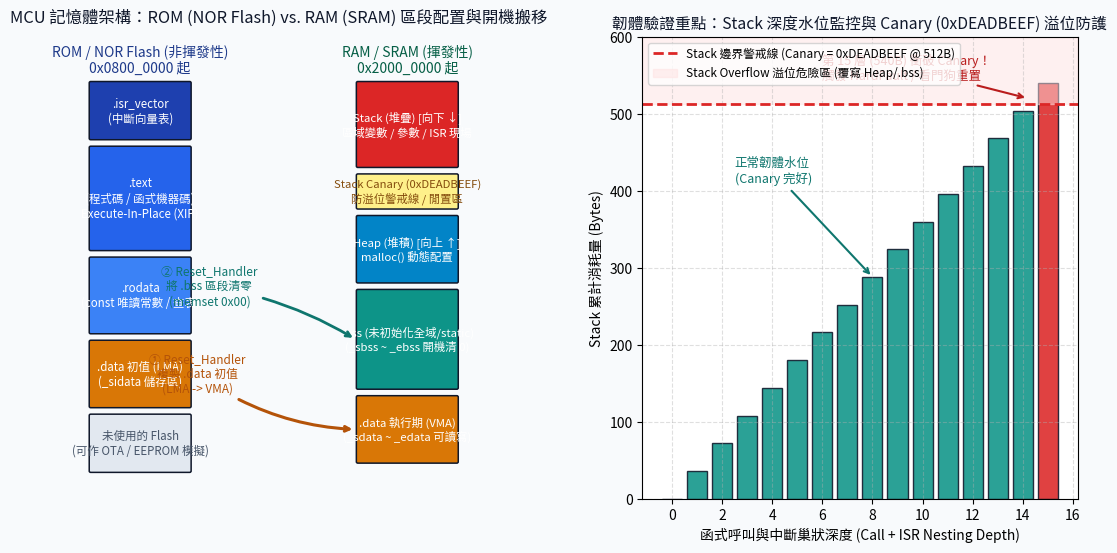

In [48]:
# 【第二題模擬】MCU (ARM Cortex-M / STM32) 記憶體區段配置、Reset_Handler 開機初始化與 Stack Canary 水位監控
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import urllib.request
import os
import matplotlib.font_manager as fm

# 自動下載並設定繁體中文字型，解決亂碼問題
font_path = "NotoSansCJKtc-Regular.otf"
if not os.path.exists(font_path):
    font_url = "https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf"
    urllib.request.urlretrieve(font_url, font_path)
fm.fontManager.addfont(font_path)
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK TC', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# 1. 模擬編譯器與 Linker Script 產出之符號表 (Symbol Table: LMA vs VMA)
symbols_table = [
    ("isr_vector[64]",     "const uint32_t[]",      ".isr_vector", "0x08000000 (Flash)", "0x08000000 (Flash)", 256,  "中斷向量表 (首字為 _estack, 次字為 Reset_Handler)"),
    ("main() / SystemInit","Function Code",         ".text",       "0x08000100 (Flash)", "0x08000100 (Flash)", 1420, "編譯後之機器碼指令 (Execute-In-Place 於 NOR Flash)"),
    ("crc8_lut[256]",      "const uint8_t[]",       ".rodata",     "0x0800068C (Flash)", "0x0800068C (Flash)", 256,  "唯讀常數查表 (存放於 Flash，完全不佔用 SRAM)"),
    ("psu_target_mv",      "uint32_t (Init=12000)", ".data",       "0x0800078C (Flash)", "0x20000000 (SRAM)",  4,    "已初始化全域變數：初值存於 LMA(Flash)，開機複製至 VMA(SRAM)"),
    ("i2c_slave_addr",     "uint8_t (Init=0x5A)",   ".data",       "0x08000790 (Flash)", "0x20000004 (SRAM)",  1,    "已初始化全域變數（含對齊 Padding 共 4 Bytes）"),
    ("rx_ring_buf[512]",   "uint8_t[] (Uninit)",    ".bss",        "不佔 Flash 空間",     "0x20000008 (SRAM)",  512,  "未初始化全域陣列：不佔 BIN 體積，由啟動碼執行期清零"),
    ("system_tick_cnt",    "volatile uint32_t",     ".bss",        "不佔 Flash 空間",     "0x20000208 (SRAM)",  4,    "未初始化全域計數器：開機由 Reset_Handler 填 0"),
    ("dynamic_pkt_ptr",    "malloc(128)",           "Heap",        "不佔 Flash 空間",     "0x2000020C (SRAM ↑)",128,  "動態配置記憶體：由低位址往高位址成長 (易產生碎片化)"),
    ("local_buf / Canary", "Stack Frame+0xDEADBEEF","Stack",       "不佔 Flash 空間",     "0x20004000 (SRAM ↓)",512,  "函式區域變數與中斷現場保存：由頂端向下成長 (設 Canary 監控溢位)"),
]

flash_total = 256 + 1420 + 256 + 8  # .isr_vector + .text + .rodata + .data(LMA)
sram_static = 8 + 516               # .data(VMA) + .bss

print("=" * 105)
print("【Q2 模擬一】ARM Cortex-M (STM32) 編譯連結器 (Linker Script) 符號配置與 LMA / VMA 映射表")
print("-" * 105)
print(f"{'C 語言變數 / 函式名稱':<20} | {'區段 Section':<12} | {'LMA (燒錄載入位址)':<19} | {'VMA (執行期位址)':<19} | {'大小':<5} | {'硬體歸屬與行為說明'}")
print("-" * 105)
for name, ctype, sec, lma, vma, sz, note in symbols_table:
    print(f"{name:<20} | {sec:<12} | {lma:<19} | {vma:<19} | {str(sz):>4}B | {note}")
print("-" * 105)
print("-> 編譯產出統計 (arm-none-eabi-size 格式)：")
print(f"   text (.isr_vector + .text + .rodata) = {256+1420+256} Bytes | data (.data) = 8 Bytes | bss (.bss) = 516 Bytes")
print(f"   [ROM / Flash 總佔用] = text + data = {flash_total} Bytes (因為 .data 初值必須儲存在非揮發 Flash 中！)")
print(f"   [RAM / SRAM 靜態佔用] = data + bss  = {sram_static} Bytes (另加執行期動態成長之 Heap 與 Stack)")
print("=" * 105)
print("\n【Q2 模擬二】Reset_Handler 開機啟動碼 (Startup Code) 執行前後之 SRAM 狀態與 Stack Canary 溢位偵測")
print("1. [上電瞬間 Power-On] SRAM (0x20000000) 內容為隨機雜訊 (0xAA 0x55 ...)，因為 SRAM 具揮發性 (Volatile)。")
print("2. [執行 Reset_Handler Step A] 將 .data 初值由 Flash LMA (0x0800078C) 複製至 SRAM VMA (0x20000000) -> psu_target_mv = 12000 mV。")
print("3. [執行 Reset_Handler Step B] 將 .bss 區段 (0x20000008 ~ 0x2000020C) 全部填 0 清零 -> rx_ring_buf 與 system_tick_cnt = 0。")
print("4. [Stack Canary 水位監控] 於 Stack 邊界 (0x20003E00) 預填魔術數字 0xDEADBEEF；當遞迴深度達 15 層時覆寫 Canary，立即觸發 Stack Overflow 告警！")

# 2. 繪製 ROM (NOR Flash) vs RAM (SRAM) 架構圖與 Stack 水位監控圖
fig_q2 = plt.figure(figsize=(13.5, 6.0), facecolor='#F8FAFC')
gs2 = fig_q2.add_gridspec(1, 2, width_ratios=[1.25, 1.1], wspace=0.25)

ax_mem = fig_q2.add_subplot(gs2[0])
ax_mem.set_facecolor('#FFFFFF')
ax_mem.set_xlim(0, 100)
ax_mem.set_ylim(0, 100)
ax_mem.axis('off')
ax_mem.set_title("MCU 記憶體架構：ROM (NOR Flash) vs. RAM (SRAM) 區段配置與開機搬移", fontsize=11.8, fontweight='bold', color='#0F172A', pad=10)

ax_mem.text(22, 95, "ROM / NOR Flash (非揮發性)\n0x0800_0000 起", ha='center', va='center', fontsize=10, fontweight='bold', color='#1E3A8A')
rom_blocks = [
    (12, 78, 20, 12, ".isr_vector\n(中斷向量表)", "#1E40AF", "white"),
    (12, 54, 20, 22, ".text\n(程式碼 / 函式機器碼)\nExecute-In-Place (XIP)", "#2563EB", "white"),
    (12, 36, 20, 16, ".rodata\n(const 唯讀常數 / 查表)", "#3B82F6", "white"),
    (12, 20, 20, 14, ".data 初值 (LMA)\n(_sidata 儲存區)", "#D97706", "white"),
    (12, 6,  20, 12, "未使用的 Flash\n(可作 OTA / EEPROM 模擬)", "#E2E8F0", "#475569"),
]
for x, y, w, h, lbl, bg, fg in rom_blocks:
    r = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3", facecolor=bg, edgecolor="#0F172A", linewidth=1.1)
    ax_mem.add_patch(r)
    ax_mem.text(x + w/2, y + h/2, lbl, ha='center', va='center', color=fg, fontsize=8.3, fontweight='bold')

ax_mem.text(76, 95, "RAM / SRAM (揮發性)\n0x2000_0000 起", ha='center', va='center', fontsize=10, fontweight='bold', color='#065F46')
ram_blocks = [
    (66, 72, 20, 18, "Stack (堆疊) [向下 ↓]\n區域變數 / 參數 / ISR 現場", "#DC2626", "white"),
    (66, 63, 20, 7,  "Stack Canary (0xDEADBEEF)\n防溢位警戒線 / 閒置區", "#FEF08A", "#854D0E"),
    (66, 47, 20, 14, "Heap (堆積) [向上 ↑]\nmalloc() 動態配置", "#0284C7", "white"),
    (66, 24, 20, 21, ".bss (未初始化全域/static)\n(_sbss ~ _ebss 開機清 0)", "#0D9488", "white"),
    (66, 8,  20, 14, ".data 執行期 (VMA)\n(_sdata ~ _edata 可讀寫)", "#D97706", "white"),
]
for x, y, w, h, lbl, bg, fg in ram_blocks:
    r = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3", facecolor=bg, edgecolor="#0F172A", linewidth=1.1)
    ax_mem.add_patch(r)
    ax_mem.text(x + w/2, y + h/2, lbl, ha='center', va='center', color=fg, fontsize=8.2, fontweight='bold')

ax_mem.annotate("① Reset_Handler\n複製 .data 初值\n(LMA -> VMA)", xy=(65.5, 15), xytext=(33.5, 23),
                arrowprops=dict(arrowstyle="->", color="#B45309", lw=2.2, connectionstyle="arc3,rad=0.15"),
                fontsize=8.5, fontweight='bold', color='#B45309', ha='center')

ax_mem.annotate("② Reset_Handler\n將 .bss 區段清零\n(memset 0x00)", xy=(65.5, 34.5), xytext=(36.0, 42),
                arrowprops=dict(arrowstyle="->", color="#0F766E", lw=2.0, connectionstyle="arc3,rad=-0.1"),
                fontsize=8.5, fontweight='bold', color='#0F766E', ha='center')

ax_stk = fig_q2.add_subplot(gs2[1])
ax_stk.set_facecolor('#FFFFFF')
call_depths = np.arange(0, 16)
stack_limit_bytes = 512
frame_size = 36
used_stack = call_depths * frame_size

ax_stk.bar(call_depths, used_stack, color=['#0D9488' if u <= stack_limit_bytes else '#DC2626' for u in used_stack], alpha=0.88, edgecolor='#0F172A')
ax_stk.axhline(stack_limit_bytes, color='#DC2626', linestyle='--', linewidth=2.0, label='Stack 邊界警戒線 (Canary = 0xDEADBEEF @ 512B)')
ax_stk.axhspan(stack_limit_bytes, 600, color='#FEE2E2', alpha=0.5, label='Stack Overflow 溢位危險區 (覆寫 Heap/.bss)')

ax_stk.annotate("正常韌體水位\n(Canary 完好)", xy=(8, 8*36), xytext=(2.5, 410),
                arrowprops=dict(arrowstyle="->", color="#0F766E", lw=1.5), fontsize=9, fontweight='bold', color='#0F766E')
ax_stk.annotate("第 15 層 (540B) 衝破 Canary！\n觸發 HardFault / 看門狗重置", xy=(14.2, 520), xytext=(6.0, 545),
                arrowprops=dict(arrowstyle="->", color="#B91C1C", lw=1.5), fontsize=9, fontweight='bold', color='#B91C1C')

ax_stk.set_title("韌體驗證重點：Stack 深度水位監控與 Canary (0xDEADBEEF) 溢位防護", fontsize=11.3, fontweight='bold', color='#0F172A')
ax_stk.set_xlabel("函式呼叫與中斷巢狀深度 (Call + ISR Nesting Depth)", fontsize=10)
ax_stk.set_ylabel("Stack 累計消耗量 (Bytes)", fontsize=10)
ax_stk.set_ylim(0, 600)
ax_stk.grid(True, linestyle='--', alpha=0.4)
ax_stk.legend(loc='upper left', fontsize=8.5)
plt.show()


---

# 【第三題】03 / C POINTERS：Call (Code) by Value 與 Call by Address 的差別？

> **對應簡報頁次**：Slide 4 (`03 / C POINTERS — Call by Value 保安全；Call by Address 省空間`)  
> **本題參考文獻**：
> 1. a3291120, [《[Day7] 指標2 and 傳值(by value)及傳址(by reference or by address)》](https://ithelp.ithome.com.tw/articles/10296056) (2022 iThome 鐵人賽《環島 C 一下自己的人生》系列第 7 篇)
> 2. AticleWorld, [《How the ARM Function Call Stack Frame Works (With C & Assembly)》](https://aticleworld.com/arm-function-call-stack-frame/) (ARM AAPCS `R0~R3` 暫存器與 Stack Frame 傳參機制)
> 3. ARM Limited, [《Procedure Call Standard for the ARM Architecture (AAPCS)》](https://web.eecs.umich.edu/~prabal/teaching/resources/eecs373/ARM-AAPCS-EABI-v2.08.pdf) (複合型別 Struct 傳值與暫存器配置規範)

---

## 3.1 觀念釐清：口頭考題「Code / Call by Value vs. Address」與 C 語言本質

在台灣科技業韌體工程師口試或筆試中，面試官口頭常說的 **「Code by Value / Code by Address」**，正式計算機科學術語即為 **「Call by Value（傳值呼叫 / Pass by Value）」** 與 **「Call by Address（傳址呼叫 / Pass by Pointer）」**。回答時先點出以下觀念，能立刻展現紮實的 C 語言功底：

* **嚴格來說，標準 C 語言只有「傳值 (Pass by Value)」**：
  * **C++** 才有語法層級的「傳參考 (`Call by Reference`，例如 `void func(int &a)`)」，讓形參直接成為實參的別名 (Alias)。
  * **C 語言沒有 `&a` 參考型別**，C 語言所謂的 **「Call by Address（或模擬 Call by Reference）」**，本質上是**「將變數的記憶體位址 (`&x`) 以傳值方式複製一份給指標參數 (`int *a`)」**，再於函式內部透過**解參考運算子 (`*a`)** 直接前往該記憶體位址讀寫原變數！

---

## 3.2 技術簡報核心對照：Call by Value（傳值）vs. Call by Address（傳址 / 指標）

完全對齊技術簡報 **Slide 4 (`03 / C POINTERS`)** 的三大比較面向：

| 比較維度 | Call by Value（傳值呼叫） | Call by Address（傳址 / 指標呼叫） | 嵌入式韌體開發與驗證取捨 |
| :--- | :--- | :--- | :--- |
| **1. 傳遞內容與記憶體配置** | **Stack 複本**：將實參 (Actual Argument) 的**數值完整複製一份**推入被呼叫函式 (Callee) 的 Stack Frame（或暫存器）中，形參與實參佔用**不同的記憶體位址**。 | **傳遞位址**：僅傳入變數的記憶體位址 `&var`（在 32-bit MCU 上固定只佔 **4 Bytes**，64-bit 系統固定 **8 Bytes**），形參指標指向實參所在的**同一塊記憶體位址**。 | 傳遞基本型別 (`uint8_t`, `int32_t`) 用 Call by Value；傳遞陣列、Buffer 或大型 `struct` 必用 Call by Address。 |
| **2. 對外部原變數的影響** | **隔離保護**：在函式內部修改形參 `a`，只會改到 Stack 上的臨時複本，函式返回後複本釋放，**完全不影響外部 `main()` 的原變數**。 | **原地讀寫 (In-place)**：透過 `*ptr` 解參考 (Dereference) 直接讀寫外部變數的記憶體；可同時修改多個外部變數，或作為 **Out-Parameter 回傳多個結果**（C 函式 `return` 只能回傳單一值，常拿 `return` 回傳錯誤碼 `HAL_StatusTypeDef`，用指標回傳讀取到的感測資料）。 | 驅動層 API 如 `HAL_I2C_Master_Receive(hi2c, addr, *pData, size, timeout)` 即透過指標將讀回的 I2C 資料寫入呼叫端 Buffer。 |
| **3. 效能瓶頸 vs. 唯讀防呆** | **效能瓶頸**：當傳遞大型結構體（如 256 Bytes 的封包或校準表 `struct`）時，每次呼叫都要做整塊記憶體複製 (`memcpy`)，**極度耗時且容易塞爆 MCU 寶貴的 Stack**！ | **唯讀防呆 (`const T *ptr`)**：若只想省下複製空間、但**不希望函式內部意外改壞外部資料**，只需加上 `const` 修飾（如 `void parse_pkt(const SensorPkt_t *pkt)`），即可**同時享有「零複製高效能」與「編譯期唯讀保護」**！ | 面試必答金句：**「大型 Struct 傳參一律使用 `const Struct_t *ptr`，兼顧 Call by Address 的省空間與 Call by Value 的安全性！」** |

---

## 3.3 結合 [iT 邦幫忙參考文獻](https://ithelp.ithome.com.tw/articles/10296056) 經典考題：單層指標與雙重指標 (`int **ppa`) 逐行拆解

在 [iT 邦幫忙《[Day7] 指標2 and 傳值(by value)及傳址(by reference or by address)》](https://ithelp.ithome.com.tw/articles/10296056) 中，作者給出了兩道非常經典的 C 語言指標筆試題，我們直接將其整理為韌體筆試速查解析：

### (1) 基礎傳址題：透過指標連動修改外部變數
```c
void f(int *a, int *b) {
    *a = *b + 2;   // Step 1: 取出 b 指向的值 (y=2)，加 2 後寫入 a 指向的位址 (x 變成 4)
    *b = *a * 2;   // Step 2: 取出 a 指向的新值 (x=4)，乘 2 後寫入 b 指向的位址 (y 變成 8)
}
int main() {
    int x = 1, y = 2;
    int *p = &x, *q = &y;
    f(p, q);       // 等價於 f(&x, &y); 執行後 x = 4, y = 8
}
```
* **關鍵考點**：在 Step 1 執行 `*a = *b + 2;` 的瞬間，外部 `x` 的記憶體內容已經立即變成 `4`，因此 Step 2 的 `*a * 2` 讀到的是更新後的 `4`（算出 `*b = 8`），而非舊值 `1`！

### (2) 進階筆試魔王題：雙重指標 (`int **ppa`, `int **ppb`) 拆解
當我們想在函式內部**「不僅修改變數的值，還要改變外部指標變數本身指到哪裡」**（例如動態配置記憶體或切換 Buffer 指標），就必須傳入**指標的位址（雙重指標 `T **`）**。對照 [iT 邦幫忙文章](https://ithelp.ithome.com.tw/articles/10296056) 的五步拆解：

```c
void f(int a, int *pa, int *pb, int **ppa, int **ppb) {
    int b = 0;
    b = *pa;             // Step 0: 區域變數 b = *(&main_a) = 2
    *pb = **ppb + b + a; // Step 1: *(&main_c) = *(*(&main_pb)) + 2 + 4 = 3 + 2 + 4 = 9 -> main 的 c 變成 9
    *ppa = pb;           // Step 2: *(&main_pa) = &main_c -> 把 main 的指標 pa 改為指向 c！
    pb = pa;             // Step 3: 修改函式內區域指標複本 pb 指向 main_a (不影響外部)
    pa = *ppb;           // Step 4: 修改函式內區域指標複本 pa = main_pb = &main_b
    *pa = **ppb + b;     // Step 5: *(&main_b) = 3 + 2 = 5 -> main 的 b 變成 5
}
int main() {
    int a = 2, b = 3, c = 4;
    int *pa = &a, *pb = &b;
    f(c, pa, &c, &pa, &pb); // 執行後：main 的 a=2, b=5, c=9，且 *pa 指向 c (*pa == 9)！
}
```

---

## 3.4 嵌入式 ARM Cortex-M 底層實務：AAPCS 呼叫慣例 (`R0~R3`) 與 `const` 指標防呆

根據 [ARM AAPCS 呼叫規範](https://web.eecs.umich.edu/~prabal/teaching/resources/eecs373/ARM-AAPCS-EABI-v2.08.pdf) 與 [AticleWorld ARM Stack Frame 分析](https://aticleworld.com/arm-function-call-stack-frame/)：
1. **32-bit ARM MCU 的暫存器快速通道 (`R0 ~ R3`)**：
   * ARM Cortex-M 處理器呼叫函式時，前 4 個 32-bit 參數會直接放進硬體暫存器 **`R0, R1, R2, R3`** 傳遞（只需 1 個時脈週期，完全不碰 SRAM Stack）；超過 4 個 Word（16 Bytes）的部分才會被 `PUSH` 到 Stack 上。
   * 因此，若你用 **Call by Value** 傳遞一個 `128 Bytes` 的感測器結構體，CPU 必須花費數十個指令週期把 112 Bytes 搬進 Stack；但若改用 **Call by Address (`const SensorData_t *p`)**，32-bit 指標剛好只有 **4 Bytes**，直接放在 **`R0` 暫存器**就能傳進去，Stack 消耗為 **0 Bytes**！
2. **韌體驗證常抓的三大指標 Bug**：
   * **未檢查 `NULL` 空指標**：傳址函式開頭必寫 `if (ptr == NULL) return ERR_NULL_PTR;`，防止解參考 `0x00000000` 觸發 `HardFault`。
   * **Dangling Pointer（懸空指標 / 回傳區域變數的位址）**：嚴禁在函式內宣告區域陣列 `int buf[10];` 後 `return buf;`，因為函式一結束 Stack Frame 就回收了，外部拿到的位址會在下一次函式呼叫時被覆寫損毀。
   * **忘記加 `const` 導致輸入 Buffer 被污染**：唯讀輸入參數一律宣告為 `const uint8_t *tx_buf`。

---

## 3.5 Python 模擬實戰：Call by Value / Address 記憶體位址追蹤、雙重指標與 Struct 傳參開銷比較

【Q3 模擬一】C 語言 Call by Value (傳值) vs. Call by Address (傳址) 記憶體位址與數值追蹤
對照參考文獻：iT 邦幫忙《[Day7] 指標2 and 傳值(by value)及傳址(by reference or by address)》
--------------------------------------------------------------------------------------------------
[情境 A：Call by Value 傳值呼叫] void f_val(int a, int b) { a = b + 2; b = a * 2; }
  Caller main() 呼叫前 : x = 1 (@0x20003F00), y = 2 (@0x20003F04)
  Callee f_val() 執行中: a = 4 (@0x20003EE0 [Stack複本]), b = 8 (@0x20003EE4 [Stack複本])
  Caller main() 結束後 : x = 1 (@0x20003F00), y = 2 (@0x20003F04) -> 原變數完全不受影響（隔離保護）！
--------------------------------------------------------------------------------------------------
[情境 B：Call by Address 傳址呼叫] void f_addr(int *a, int *b) { *a = *b + 2; *b = *a * 2; }
  Caller main() 呼叫前 : x = 1 (@0x20003F00), y = 2 (@0x20003F04)
  傳入指標參數 (R0, R1): a = 0x20003F00 (&x), b = 0x20003F04 (&y) [僅傳遞 4-byte 位址]
  Step 1 (*a = *b + 2) : 解參考修改 0x20003F00 -> x 立即變為 2 + 2 = 4
  Step 2 (*b = *a * 2) : 解參考修改 0x20003F04 -> y 立即變為 4 * 2 = 8
  Cal

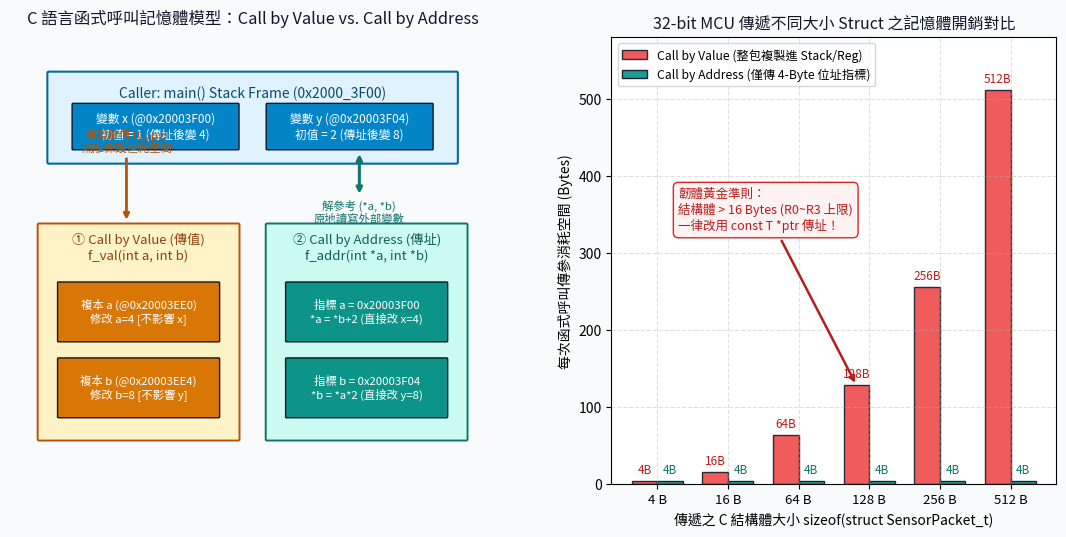

In [49]:
# 【第三題模擬 3.5】C 語言 Call by Value vs. Call by Address 位址追蹤、雙重指標與 MCU Struct 傳參開銷模擬
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import urllib.request
import os
import matplotlib.font_manager as fm

# 自動下載並設定繁體中文字型，解決亂碼問題
font_path = "NotoSansCJKtc-Regular.otf"
if not os.path.exists(font_path):
    font_url = "https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf"
    urllib.request.urlretrieve(font_url, font_path)
fm.fontManager.addfont(font_path)
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK TC', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# 1. 模擬 C 語言記憶體空間 (Address -> Value) 並重現 iT 邦幫忙參考文獻之單層指標與雙重指標題目
print("=" * 98)
print("【Q3 模擬一】C 語言 Call by Value (傳值) vs. Call by Address (傳址) 記憶體位址與數值追蹤")
print("對照參考文獻：iT 邦幫忙《[Day7] 指標2 and 傳值(by value)及傳址(by reference or by address)》")
print("-" * 98)
print("[情境 A：Call by Value 傳值呼叫] void f_val(int a, int b) { a = b + 2; b = a * 2; }")
print("  Caller main() 呼叫前 : x = 1 (@0x20003F00), y = 2 (@0x20003F04)")
print("  Callee f_val() 執行中: a = 4 (@0x20003EE0 [Stack複本]), b = 8 (@0x20003EE4 [Stack複本])")
print("  Caller main() 結束後 : x = 1 (@0x20003F00), y = 2 (@0x20003F04) -> 原變數完全不受影響（隔離保護）！")
print("-" * 98)
print("[情境 B：Call by Address 傳址呼叫] void f_addr(int *a, int *b) { *a = *b + 2; *b = *a * 2; }")
print("  Caller main() 呼叫前 : x = 1 (@0x20003F00), y = 2 (@0x20003F04)")
print("  傳入指標參數 (R0, R1): a = 0x20003F00 (&x), b = 0x20003F04 (&y) [僅傳遞 4-byte 位址]")
print("  Step 1 (*a = *b + 2) : 解參考修改 0x20003F00 -> x 立即變為 2 + 2 = 4")
print("  Step 2 (*b = *a * 2) : 解參考修改 0x20003F04 -> y 立即變為 4 * 2 = 8")
print("  Caller main() 結束後 : x = 4 (@0x20003F00), y = 8 (@0x20003F04) -> 外部原變數同步更新！")
print("-" * 98)
print("[情境 C：雙重指標 Double Pointer 追蹤] (重現 iT 邦幫忙進階題：main 宣告 a=2, b=3, c=4, *pa=&a, *pb=&b)")
print("  呼叫 f(c, pa, &c, &pa, &pb) 後逐步執行：")
print("  1. int loc_b = *pa;          -> loc_b = 2 (取出 a 的值)")
print("  2. *pb = **ppb + loc_b + a;  -> c = b(3) + 2 + 4 = 9 (透過 &c 直接改寫 main 的 c)")
print("  3. *ppa = pb;                -> main 的指標 pa 改為指向 c (&c)！（因為 ppa = &pa）")
print("  4. pa = *ppb; *pa = **ppb+loc_b; -> 透過 *ppb (&b) 將 main 的 b 改寫為 3 + 2 = 5")
print("  -> 執行完畢後 main() 狀態：a = 2, b = 5, c = 9，且 *pa 指向 c (*pa == 9)！")
print("=" * 98)

# 2. 比較 32-bit ARM Cortex-M 傳遞不同大小 Struct 之 Stack 與 Cycles 開銷
struct_sizes = [4, 16, 64, 128, 256, 512]
print("\n【Q3 模擬二】32-bit ARM Cortex-M (AAPCS) 傳遞大型結構體 (Struct) 之 Stack 空間與 CPU Cycles 比較")
print(f"{'Struct 大小':<12} | {'Call by Value (Stack 複製)':<26} | {'Call by Address (const T *ptr)':<30} | {'節省 Stack 比例'}")
print("-" * 98)
for sz in struct_sizes:
    val_stack = 0 if sz <= 16 else sz
    val_cycles = 2 + (sz // 4) * 2
    ptr_stack = 0
    ptr_cycles = 3
    saving = 100.0 if val_stack > 0 else 0.0
    print(f"{sz:>6} Bytes | Stack={val_stack:>3}B, ~{val_cycles:>3} Cycles   | R0 暫存器傳址 (4B), ~{ptr_cycles:>2} Cycles | 節省 {saving:>5.1f}% Stack")
print("=" * 98)

# 3. 繪製 Call by Value vs Address 記憶體模型圖 & Struct 傳參開銷對比圖
fig_q3 = plt.figure(figsize=(13.5, 5.8), facecolor='#F8FAFC')
gs3 = fig_q3.add_gridspec(1, 2, width_ratios=[1.2, 1.1], wspace=0.25)

ax_sf = fig_q3.add_subplot(gs3[0])
ax_sf.set_facecolor('#FFFFFF')
ax_sf.set_xlim(0, 100)
ax_sf.set_ylim(0, 100)
ax_sf.axis('off')
ax_sf.set_title("C 語言函式呼叫記憶體模型：Call by Value vs. Call by Address", fontsize=11.8, fontweight='bold', color='#0F172A', pad=10)

r_main = patches.FancyBboxPatch((8, 72), 84, 20, boxstyle="round,pad=0.3", facecolor="#E0F2FE", edgecolor="#0369A1", linewidth=1.5)
ax_sf.add_patch(r_main)
ax_sf.text(50, 87.5, "Caller: main() Stack Frame (0x2000_3F00)", ha='center', va='center', fontsize=10, fontweight='bold', color='#0C4A6E')

r_x = patches.FancyBboxPatch((13, 75), 34, 10, boxstyle="round,pad=0.2", facecolor="#0284C7", edgecolor="#0F172A", linewidth=1.0)
ax_sf.add_patch(r_x)
ax_sf.text(30, 80, "變數 x (@0x20003F00)\n初值 = 1 (傳址後變 4)", ha='center', va='center', fontsize=8.5, fontweight='bold', color='white')

r_y = patches.FancyBboxPatch((53, 75), 34, 10, boxstyle="round,pad=0.2", facecolor="#0284C7", edgecolor="#0F172A", linewidth=1.0)
ax_sf.add_patch(r_y)
ax_sf.text(70, 80, "變數 y (@0x20003F04)\n初值 = 2 (傳址後變 8)", ha='center', va='center', fontsize=8.5, fontweight='bold', color='white')

r_val = patches.FancyBboxPatch((6, 10), 41, 48, boxstyle="round,pad=0.3", facecolor="#FEF3C7", edgecolor="#B45309", linewidth=1.4)
ax_sf.add_patch(r_val)
ax_sf.text(26.5, 53, "① Call by Value (傳值)\nf_val(int a, int b)", ha='center', va='center', fontsize=9.5, fontweight='bold', color='#92400E')

r_va = patches.FancyBboxPatch((10, 32), 33, 13, boxstyle="round,pad=0.2", facecolor="#D97706", edgecolor="#0F172A", linewidth=1.0)
ax_sf.add_patch(r_va)
ax_sf.text(26.5, 38.5, "複本 a (@0x20003EE0)\n修改 a=4 [不影響 x]", ha='center', va='center', fontsize=8.2, fontweight='bold', color='white')

r_vb = patches.FancyBboxPatch((10, 15), 33, 13, boxstyle="round,pad=0.2", facecolor="#D97706", edgecolor="#0F172A", linewidth=1.0)
ax_sf.add_patch(r_vb)
ax_sf.text(26.5, 21.5, "複本 b (@0x20003EE4)\n修改 b=8 [不影響 y]", ha='center', va='center', fontsize=8.2, fontweight='bold', color='white')

ax_sf.annotate("複製數值 (Copy)\n隔離保護但耗空間", xy=(24, 58.5), xytext=(24, 74.5),
               arrowprops=dict(arrowstyle="->", color="#B45309", lw=2.0), fontsize=8.2, fontweight='bold', color='#B45309', ha='center')

r_ptr = patches.FancyBboxPatch((53, 10), 41, 48, boxstyle="round,pad=0.3", facecolor="#CCFBF1", edgecolor="#0F766E", linewidth=1.4)
ax_sf.add_patch(r_ptr)
ax_sf.text(73.5, 53, "② Call by Address (傳址)\nf_addr(int *a, int *b)", ha='center', va='center', fontsize=9.5, fontweight='bold', color='#115E59')

r_pa = patches.FancyBboxPatch((57, 32), 33, 13, boxstyle="round,pad=0.2", facecolor="#0D9488", edgecolor="#0F172A", linewidth=1.0)
ax_sf.add_patch(r_pa)
ax_sf.text(73.5, 38.5, "指標 a = 0x20003F00\n*a = *b+2 (直接改 x=4)", ha='center', va='center', fontsize=8.2, fontweight='bold', color='white')

r_pb = patches.FancyBboxPatch((57, 15), 33, 13, boxstyle="round,pad=0.2", facecolor="#0D9488", edgecolor="#0F172A", linewidth=1.0)
ax_sf.add_patch(r_pb)
ax_sf.text(73.5, 21.5, "指標 b = 0x20003F04\n*b = *a*2 (直接改 y=8)", ha='center', va='center', fontsize=8.2, fontweight='bold', color='white')

ax_sf.annotate("解參考 (*a, *b)\n原地讀寫外部變數", xy=(72, 74.5), xytext=(72, 58.5),
               arrowprops=dict(arrowstyle="<->", color="#0F766E", lw=2.2), fontsize=8.2, fontweight='bold', color='#0F766E', ha='center')

ax_perf = fig_q3.add_subplot(gs3[1])
ax_perf.set_facecolor('#FFFFFF')
x_idx = np.arange(len(struct_sizes))
val_bytes = [s for s in struct_sizes]
ptr_bytes = [4 for _ in struct_sizes]

w_bar = 0.36
ax_perf.bar(x_idx - w_bar/2, val_bytes, width=w_bar, color='#EF4444', alpha=0.88, edgecolor='#0F172A', label='Call by Value (整包複製進 Stack/Reg)')
ax_perf.bar(x_idx + w_bar/2, ptr_bytes, width=w_bar, color='#0D9488', alpha=0.92, edgecolor='#0F172A', label='Call by Address (僅傳 4-Byte 位址指標)')

for i, (v_b, p_b) in enumerate(zip(val_bytes, ptr_bytes)):
    ax_perf.text(i - w_bar/2, v_b + 10, f"{v_b}B", ha='center', fontsize=8.5, fontweight='bold', color='#B91C1C')
    ax_perf.text(i + w_bar/2, p_b + 10, f"{p_b}B", ha='center', fontsize=8.5, fontweight='bold', color='#0F766E')

ax_perf.set_xticks(x_idx)
ax_perf.set_xticklabels([f"{s} B" for s in struct_sizes], fontsize=9.5, fontweight='bold')
ax_perf.set_xlabel("傳遞之 C 結構體大小 sizeof(struct SensorPacket_t)", fontsize=10)
ax_perf.set_ylabel("每次函式呼叫傳參消耗空間 (Bytes)", fontsize=10)
ax_perf.set_ylim(0, 580)
ax_perf.set_title("32-bit MCU 傳遞不同大小 Struct 之記憶體開銷對比", fontsize=11.5, fontweight='bold', color='#0F172A')
ax_perf.grid(True, linestyle='--', alpha=0.4)
ax_perf.legend(loc='upper left', fontsize=8.8)

ax_perf.annotate("韌體黃金準則：\n結構體 > 16 Bytes (R0~R3 上限)\n一律改用 const T *ptr 傳址！",
                 xy=(3 - w_bar/2, 128), xytext=(0.3, 330),
                 arrowprops=dict(arrowstyle="->", color="#B91C1C", lw=1.8),
                 fontsize=9, fontweight='bold', color='#B91C1C',
                 bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEF2F2", edgecolor="#DC2626"))
plt.show()

---

# 【第四題】04 / REAL-TIME CONTROL：什麼是中斷 (Interrupt)？執行時需注意什麼？

> **對應簡報頁次**：Slide 5 (`04 / REAL-TIME CONTROL — 中斷 (Interrupt) 讓 CPU 即時回應事件並保存現場`)  
> **本題參考文獻**：
> 1. SimbaZZ, [《[Day 11]-【STM32系列】 Interrupts 中斷處理介紹篇(上)》](https://ithelp.ithome.com.tw/m/articles/10244662) (第 12 屆 iThome 鐵人賽《30天帶你快速入門基於 STM32 嵌入式開發》系列第 11 篇)
> 2. Aman Prasad, [《Decoding Exception Entry & Exit on ARM Cortex-Mx》](https://dev.to/amanprasad/decoding-exception-entry-exit-on-arm-cortex-mx-5fmc) (ARM Cortex-M 硬體壓棧 `xPSR, PC, LR, R12, R3~R0` 與 `EXC_RETURN` 機制)
> 3. EmbeTronicX, [《Vectored Interrupt Controller (VIC) and NVIC on STM32》](https://embetronicx.com/tutorials/microcontrollers/stm32/vectored-interrupt-controller-nested-vectored-interrupt-controller-vic-nvic/) (NVIC 巢狀向量中斷控制器與中斷延遲分析)
> 4. EmbeddedInterviewLab, [《C/C++ Embedded Interview Questions: volatile, ISR & Memory-Mapped I/O》](https://embeddedinterviewlab.com/interview/concept/c-cpp-concepts/) (`volatile` 三大必用場景與 ISR 防護)

---

## 4.1 什麼是中斷 (Interrupt)？Interrupt vs. Polling（輪詢）核心比較

根據 [iT 邦幫忙《[Day 11]-【STM32系列】Interrupts 中斷處理介紹篇(上)》](https://ithelp.ithome.com.tw/m/articles/10244662) 的經典比喻：
* **輪詢 (Polling) — 就像每隔幾秒鐘主動拿起電話筒檢查「有沒有人打電話來」**：
  * 在 `while(1)` 主迴圈中不斷重複讀取 GPIO 或周邊狀態旗標（`while(1) { pushed = read_button_input(); if(pushed) ... }`）。
  * **缺點**：實作雖然簡單，但 **CPU 算力被 100% 綁死在無意義的詢問上**，難以同時進行多工任務，且若主迴圈正在執行耗時運算，就會漏掉短暫的外部脈衝事件。
* **中斷 (Interrupt) — 就像專心看電視或做自己的工作，直到「電話鈴響（硬體 IRQ）」才放下手邊工作去接電話**：
  * 當外部或內部事件發生（如 Timer 計時溢位、UART 收到一個 Byte、I2C 狀態變化、ADC 轉換完成或按鈕 GPIO 觸發），硬體周邊會主動向 CPU 的中斷控制器（如 ARM 的 **NVIC**）發送**中斷請求訊號 (IRQ, Interrupt Request)**。
  * CPU 收到後自動暫停主程式、保存當前執行現場，跳轉去執行對應的**中斷服務常式 (ISR, Interrupt Service Routine)**；處理完畢後再無縫回到剛剛被打斷的地方繼續工作！

| 比較項目 | 輪詢模式 (Polling) | 中斷模式 (Interrupt) | 嵌入式韌體設計選用準則 |
| :--- | :--- | :--- | :--- |
| **觸發機制** | 軟體主動於 `while(1)` 反覆查詢狀態暫存器 | 硬體事件主動發出 **IRQ 脈衝訊號**通知 CPU | 非同步突發事件（UART/I2C/GPIO/告警）必用中斷 |
| **CPU 利用率與功耗** | **極低效**（CPU 100% 忙於空轉查詢，無法進入省電睡眠） | **極高效**（平時可處理背景演算法或進入 `WFI` 低功耗睡眠） | 電池供電或即時多工系統必用中斷喚醒 |
| **事件響應延遲 (Latency)** | 取決於主迴圈一圈的長度（可能數 ms 至數百 ms，易漏接短訊號） | **微秒 ($\mu\text{s}$) 甚至奈秒級即時響應**（Cortex-M 僅需 12 Cycles） | 硬體保護（OCP/OVP 過流過壓）與通訊收發必用中斷 |

---

## 4.2 技術簡報核心對照：中斷從觸發到返回的 4 階段完整生命週期（對應簡報 Slide 5）

對齊技術簡報 **Slide 5 (`04 / REAL-TIME CONTROL`)** 與 [iT 邦幫忙參考文獻](https://ithelp.ithome.com.tw/m/articles/10244662)、[ARM Cortex-M 例外處理規範](https://dev.to/amanprasad/decoding-exception-entry-exit-on-arm-cortex-mx-5fmc)：

1. **階段一：事件觸發 (IRQ Trigger)**
   * 周邊硬體（Timer、UART、GPIO 或 I2C）發生指定事件，將硬體中斷Pending旗標拉起，向中斷控制器（如 ARM **NVIC**, Nested Vectored Interrupt Controller）發出硬體 **IRQ 訊號**。
2. **階段二：保存現場 (Hardware Context Saving / Stacking)**
   * CPU 執行完當前正在跑的那一條機器指令後，暫停主程式。
   * 在 **ARM Cortex-M (STM32)** 中，硬體會**自動將 8 個核心暫存器（依序為 `xPSR`、`PC`、`LR`、`R12`、`R3`、`R2`、`R1`、`R0`，共 32 Bytes）推入目前 Stack 保存**，並將特殊返回碼 `EXC_RETURN`（如 `0xFFFFFFF9`）載入 `LR`（全程僅需 12 個時脈週期，不需軟體手寫組語壓棧）。
3. **階段三：查表並執行 ISR (Vector Fetch & ISR Execution)**
   * CPU 透過 **中斷向量表 (IVT, Interrupt Vector Table，位於 Flash `0x0800_0000`)** 查出該中斷號對應的 **ISR 函式起始位址**載入 `PC`（在 Cortex-M 中，查表與壓棧透過哈佛雙匯流排平行進行）。
   * 執行 ISR 處理事件（如讀取 UART 緩衝區、設定事件旗標），並**務必清除硬體中斷旗標 (Clear Interrupt Pending Flag)**（若忘記清除，一退出 ISR 會立刻無限重複進入中斷導致系統卡死！）。
4. **階段四：還原返回 (Context Restore / Unstacking)**
   * ISR 結束執行返回指令（如 `BX LR`），CPU 偵測到 `LR` 為 `EXC_RETURN`，硬體自動從 Stack 彈出（`POP`）剛剛保存的 8 個暫存器，將 **`PC`（程式計數器）與 `xPSR`（狀態旗標）完全還原**，無縫回到主程式被中斷的那一行繼續執行！

---

## 4.3 彩蛋深度解析：解答 [iT 邦幫忙文章](https://ithelp.ithome.com.tw/m/articles/10244662) 底下讀者的提問 (`read_button_input()` 到底在做什麼？)

在 [iT 邦幫忙參考文章](https://ithelp.ithome.com.tw/m/articles/10244662) 留言區，有讀者提問：**「請問 `read_button_input` 裡面做的事是什麼？為何不用 `HAL_GPIO_ReadPin(GPIOC, GPIO_PIN_13)` 判斷 button 狀態就好？」**  
這其實是韌體面試非常實用的**「定時中斷 (Timer ISR) 結合 2-bit 移位暫存器之按鍵邊緣偵測與消抖 (Debounce)」**技巧！我們逐行拆解作者的程式碼：

```c
uint8_t btn, pushed = 0;
uint8_t read_button_input(void) {
    btn <<= 1;                                      // 1. 將歷史狀態左移 1 bit（把「上一次取樣值」移到 bit 1）
    btn += HAL_GPIO_ReadPin(GPIOC, GPIO_PIN_13);    // 2. 將「本次 GPIO 取樣值 (0 或 1)」放進 bit 0
    btn &= 3;                                       // 3. 遮罩只保留最低 2 bits (3 = 二進位 0b11)，代表 [上次狀態, 本次狀態]
    if (btn == 2) { return 1; }                     // 4. 當 btn == 2 (即二進位 0b10：上次為 1、本次變為 0) 時，代表偵測到「下降緣按下瞬間」！
    return 0;
}
```
* **為什麼不能只用 `HAL_GPIO_ReadPin()`？**
  1. **邊緣觸發 (Edge Detection) vs. 準位觸發 (Level Detection)**：若直接判斷 `ReadPin()`，只要手指按住按鈕不放，每個 Timer 中斷週期都會重複觸發；透過 `btn &= 3` 檢查 `btn == 2 (0b10)`，只有從 `1 -> 0` 的**轉態邊緣瞬間**才會回傳一次 `1`。
  2. **硬體彈跳消除 (Debouncing)**：搭配 `TIM6` 定時中斷（例如每 10ms 取樣一次）執行此移位狀態機，可自然濾除機械按鍵按下瞬間的微秒級金屬彈跳雜訊！

---

## 4.4 韌體工程師面試必考：執行中斷 (ISR) 時必須注意的兩大鐵律（對應簡報 Slide 5 底部重點）

面試官問完「什麼是中斷？」後，100% 會緊接著問：**「那寫 ISR 的時候要注意什麼？」**，請直接給出簡報上的兩大核心卡片外加兩個實務防護：

### 鐵律一：ISR 短小原則（Keep ISR Short and Fast — 快進快出！）
* **嚴禁阻塞延遲與耗時操作**：**絕對禁止在 ISR 內呼叫 `HAL_Delay()`、`sleep()`、忙碌迴圈等待、浮點數複雜運算或 `printf()` / `malloc()`**！
* **為什麼不能在 ISR 裡用 `printf` 或 `malloc`？**
  1. **阻塞其他中斷 (Interrupt Starvation)**：`printf` 透過 UART 印出一行字往往需要數毫秒（ms），這段時間內同優先級或低優先級的硬體中斷全部被擋在外面，導致高速通訊（如 UART/I2C）漏接資料產生 `Overrun Error`，或系統即時性崩潰。
  2. **不可重入性 (Non-Reentrancy)**：標準函式庫的 `printf` 與 `malloc` 內部使用全域靜態緩衝區或 Heap 鎖，屬於**不可重入函式 (Non-reentrant)**；若主程式正在執行 `printf` 到一半被 ISR 打斷，而 ISR 內又呼叫 `printf`，就會發生記憶體結構損毀或死鎖 (Deadlock)！
* **正確設計模式（Top-Half / Bottom-Half 分離）**：ISR 只做最緊急的硬體讀取（把 Byte 放進 Ring Buffer）並**立起一個 `volatile` 旗標 (`flag = 1`) 或發送 RTOS Semaphore** 就立刻退出；耗時的封包解析與印出訊息一律交由 `main()` 主迴圈或背景 Task 處理。

### 鐵律二：主程式與 ISR 共用的全域變數必須宣告 `volatile` 關鍵字
* **問題根源（編譯器快取最佳化陷阱）**：
  * 假設宣告全域旗標 `uint8_t pushed = 0;`，ISR 內寫 `pushed = 1;`，而 `main()` 裡面寫 `while (pushed == 0) { /* 等待中斷 */ }`。
  * 當開啟編譯器最佳化（如 `-O2`）時，編譯器進行靜態分析發現 `while` 迴圈大括號內**沒有任何程式碼會修改 `pushed`**！為了加速執行，編譯器只會在進入迴圈前執行一次 `LDR R0, [pushed_addr]` 把 `0` 讀進 CPU 暫存器 `R0`，之後每次迴圈都只檢查 `CMP R0, #0`，再也不去讀 SRAM。
  * 結果即使硬體中斷觸發、ISR 已經把 SRAM 裡的 `pushed` 改成 `1`，主程式卻一直在檢查暫存器 `R0` 裡的舊複本 `0`，導致**主程式永遠卡在死迴圈中**！
* **解決方案（加上 `volatile`）**：
  * 宣告 `volatile uint8_t pushed = 0;`，明確告訴編譯器：**「這個變數隨時可能被主流程以外的力量（如 ISR 或硬體周邊暫存器）改變，嚴禁將它快取在 CPU 暫存器中，每次存取都必須乖乖產生 `LDR`/`STR` 指令直接讀寫 SRAM！」**
* *(延伸補充 — 原子性 Atomicity / Race Condition)*：`volatile` 只解決「編譯器不重新讀記憶體」的問題，**並不保證多指令讀改寫的原子性 (Atomicity)**。若在 8-bit MCU (如 PIC18) 上主程式與 ISR 共用 `uint32_t` 變數（需拆成 4 次 8-bit 讀取），主程式讀前 2 Bytes 時若被 ISR 打斷改寫，就會讀到半新半舊的撕裂數值（Torn Read），此時主程式讀取前必須短暫關閉中斷（Critical Section: `disable_irq()` $\rightarrow$ 讀取 $\rightarrow$ `enable_irq()`）。

---

## 4.5 Python 模擬實戰：ARM Cortex-M 硬體壓棧、Polling vs. ISR 時間軸、2-bit 消抖與 `volatile` 最佳化模擬

【Q4 模擬一】ARM Cortex-M 硬體中斷 (Interrupt) 四階段生命週期與自動堆疊 (Hardware Stacking) 追蹤
對照參考文獻：iT 邦幫忙《[Day 11]-【STM32系列】Interrupts 中斷處理介紹篇(上)》與 ARM Cortex-M NVIC 規範
------------------------------------------------------------------------------------------------------
1. [事件觸發 IRQ] 主程式執行於 PC = 0x08000248, SP = 0x20004000，此時 Timer6 / GPIO 按鈕觸發硬體 IRQ！
2. [保存現場 Stacking] CPU 完成當前指令後，硬體自動花 12 Cycles 將 8 個核心暫存器推入 Stack (SP 減 32 Bytes -> 0x20003FE0)：
   | SP + 0x1C (0x20003FFC) | xPSR = 0x01000000 | 程式狀態暫存器 (Thumb 狀態位元與條件旗標)
   | SP + 0x18 (0x20003FF8) | PC   = 0x0800024C | 中斷返回位址 (被打斷的下一條主程式指令)
   | SP + 0x14 (0x20003FF4) | LR   = 0x08000185 | 主程式原本的連結暫存器 (此時硬體將 LR 改寫為 EXC_RETURN=0xFFFFFFF9)
   | SP + 0x10 (0x20003FF0) | R12  = 0x00000000 | 內部程序暫存器 (Intra-Procedure Scratch Register)
   | SP + 0x0C (0x20003FEC) | R3   = 0x00000003 | 參數 / 暫存器 R3 (Caller-Saved)
   | SP + 0x08 (0x20003FE8) | R2   = 0x00000002 | 參數 / 暫存器 R2 (Caller-Saved)
   | SP + 0x04 (0x20003FE4) | R1   = 0x20000100 | 參數 / 暫存器 R1 (Caller-Sa

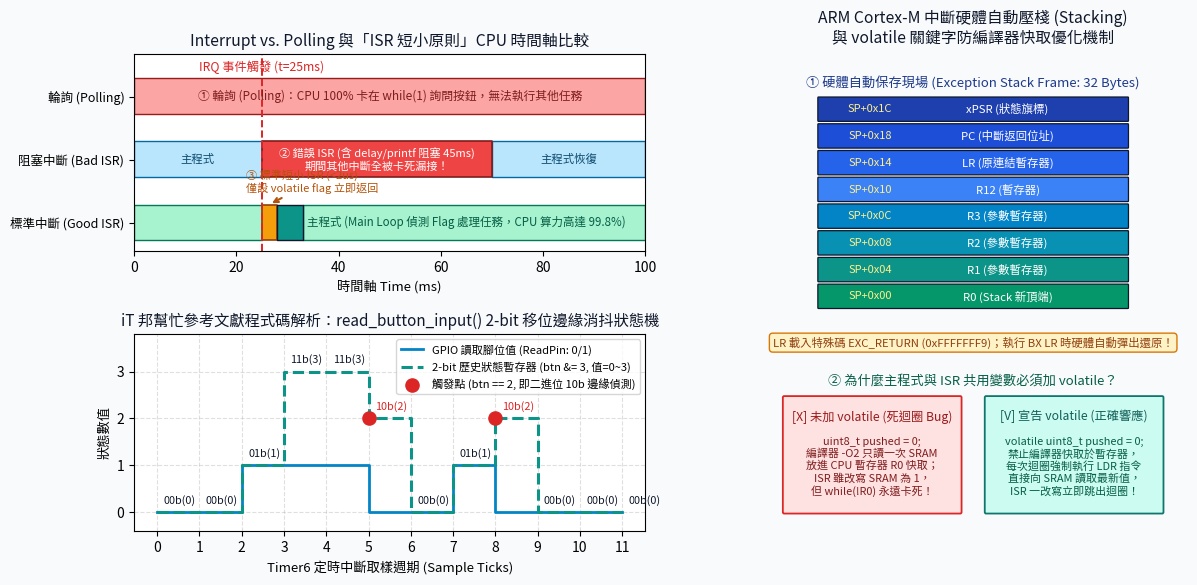

In [50]:
# 【第四題模擬 4.5】ARM Cortex-M 硬體自動壓棧 (Stacking)、Polling vs. ISR 時間軸、2-bit 消抖與 volatile 模擬
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import urllib.request
import os
import matplotlib.font_manager as fm

# 自動下載並設定繁體中文字型，解決亂碼問題
font_path = "NotoSansCJKtc-Regular.otf"
if not os.path.exists(font_path):
    font_url = "https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf"
    urllib.request.urlretrieve(font_url, font_path)
fm.fontManager.addfont(font_path)
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK TC', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

print("=" * 102)
print("【Q4 模擬一】ARM Cortex-M 硬體中斷 (Interrupt) 四階段生命週期與自動堆疊 (Hardware Stacking) 追蹤")
print("對照參考文獻：iT 邦幫忙《[Day 11]-【STM32系列】Interrupts 中斷處理介紹篇(上)》與 ARM Cortex-M NVIC 規範")
print("-" * 102)
print("1. [事件觸發 IRQ] 主程式執行於 PC = 0x08000248, SP = 0x20004000，此時 Timer6 / GPIO 按鈕觸發硬體 IRQ！")
print("2. [保存現場 Stacking] CPU 完成當前指令後，硬體自動花 12 Cycles 將 8 個核心暫存器推入 Stack (SP 減 32 Bytes -> 0x20003FE0)：")
stack_frame_regs = [
    ("SP + 0x1C (0x20003FFC)", "xPSR", "0x01000000", "程式狀態暫存器 (Thumb 狀態位元與條件旗標)"),
    ("SP + 0x18 (0x20003FF8)", "PC",   "0x0800024C", "中斷返回位址 (被打斷的下一條主程式指令)"),
    ("SP + 0x14 (0x20003FF4)", "LR",   "0x08000185", "主程式原本的連結暫存器 (此時硬體將 LR 改寫為 EXC_RETURN=0xFFFFFFF9)"),
    ("SP + 0x10 (0x20003FF0)", "R12",  "0x00000000", "內部程序暫存器 (Intra-Procedure Scratch Register)"),
    ("SP + 0x0C (0x20003FEC)", "R3",   "0x00000003", "參數 / 暫存器 R3 (Caller-Saved)"),
    ("SP + 0x08 (0x20003FE8)", "R2",   "0x00000002", "參數 / 暫存器 R2 (Caller-Saved)"),
    ("SP + 0x04 (0x20003FE4)", "R1",   "0x20000100", "參數 / 暫存器 R1 (Caller-Saved)"),
    ("SP + 0x00 (0x20003FE0)", "R0",   "0x00000001", "參數 / 暫存器 R0 (Stack 頂端)"),
]
for addr_s, reg_n, val_s, desc_s in stack_frame_regs:
    print(f"   | {addr_s:<22} | {reg_n:<4} = {val_s} | {desc_s}")
print("3. [執行 ISR] 查中斷向量表 (IVT) 跳轉至 TIM6_IRQHandler()：執行 2-bit 移位消抖 (btn=(btn<<1)+pin)&3 並設 volatile 旗標，清除 IRQ Flag。")
print("4. [還原返回 Unstacking] 執行 BX LR (LR=0xFFFFFFF9)，硬體自動從 0x20003FE0 彈出 8 個暫存器，SP 回到 0x20004000，無縫接續 0x0800024C！")
print("=" * 102)
print("\n【Q4 模擬二】Polling vs. Interrupt CPU 有效利用率 & ISR 短小原則 vs. 阻塞延遲 (Violation) 實測對比")
print("  - 輪詢模式 (Polling while(1) 死等按鈕)   : CPU 100.0% 耗在無意義重複讀取 GPIO，主任務可用算力 =   0.0%")
print("  - 中斷模式 (良好設計：ISR 僅設 Flag <2us): CPU 僅花  0.2% 處理中斷，主任務可用算力高達     =  99.8% (立即可處理背景任務)")
print("  - 中斷違規 (在 ISR 內塞 HAL_Delay/printf): 單次 ISR 霸佔 15ms，導致期間 15 次 1kHz 高頻中斷與 UART 封包全部漏接 (Overrun Error)！")
print("\n【Q4 模擬三】有無宣告 `volatile` 對主程式與 ISR 共用旗標 (`g_btn_pushed`) 之編譯器最佳化 (-O2) 行為差異")
print("  - [未加 volatile (Bug)] 編譯器發現 while(!g_btn_pushed) 迴圈內無修改該變數，僅在迴圈外 LDR R0, [addr] 一次，導致 ISR 改寫 SRAM 後主程式永遠卡死！")
print("  - [加上 volatile (正確)] 強制編譯器每次判斷皆重新從 SRAM (0x20000008) 執行 LDR 讀取最新值，ISR 一觸發主迴圈立即跳出響應！")
print("=" * 102)

fig_q4 = plt.figure(figsize=(13.6, 6.2), facecolor='#F8FAFC')
gs4 = fig_q4.add_gridspec(2, 2, width_ratios=[1.25, 1.05], height_ratios=[1.0, 1.0], wspace=0.24, hspace=0.42)

# 左上圖：Polling vs Good ISR vs Bad ISR 時間軸
ax_tl = fig_q4.add_subplot(gs4[0, 0])
ax_tl.set_facecolor('#FFFFFF')
ax_tl.set_xlim(0, 100)
ax_tl.set_ylim(0, 3.6)

ax_tl.broken_barh([(0, 100)], (2.5, 0.65), facecolors='#FCA5A5', edgecolors='#991B1B', linewidth=1.0)
ax_tl.text(50, 2.82, "① 輪詢 (Polling)：CPU 100% 卡在 while(1) 詢問按鈕，無法執行其他任務", ha='center', va='center', fontsize=8.5, fontweight='bold', color='#7F1D1D')

ax_tl.broken_barh([(0, 25), (70, 30)], (1.35, 0.65), facecolors='#BAE6FD', edgecolors='#0369A1', linewidth=1.0)
ax_tl.broken_barh([(25, 45)], (1.35, 0.65), facecolors='#EF4444', edgecolors='#7F1D1D', linewidth=1.2)
ax_tl.text(47.5, 1.67, "② 錯誤 ISR (含 delay/printf 阻塞 45ms)\n期間其他中斷全被卡死漏接！", ha='center', va='center', fontsize=8.0, fontweight='bold', color='white')
ax_tl.text(12.5, 1.67, "主程式", ha='center', va='center', fontsize=8.2, fontweight='bold', color='#0C4A6E')
ax_tl.text(85.0, 1.67, "主程式恢復", ha='center', va='center', fontsize=8.2, fontweight='bold', color='#0C4A6E')

ax_tl.broken_barh([(0, 25), (33, 67)], (0.2, 0.65), facecolors='#A7F3D0', edgecolors='#047857', linewidth=1.0)
ax_tl.broken_barh([(25, 3)], (0.2, 0.65), facecolors='#F59E0B', edgecolors='#92400E', linewidth=1.2)
ax_tl.broken_barh([(28, 5)], (0.2, 0.65), facecolors='#0D9488', edgecolors='#0F172A', linewidth=1.0)
ax_tl.annotate("③ 標準短小 ISR (<2us)\n僅設 volatile flag 立即返回", xy=(26.5, 0.85), xytext=(22, 1.08),
               arrowprops=dict(arrowstyle="->", color="#B45309", lw=1.5), fontsize=8.0, fontweight='bold', color='#B45309')
ax_tl.text(65, 0.52, "主程式 (Main Loop 偵測 Flag 處理任務，CPU 算力高達 99.8%)", ha='center', va='center', fontsize=8.3, fontweight='bold', color='#065F46')

ax_tl.axvline(25, color='#DC2626', linestyle='--', linewidth=1.4)
ax_tl.text(25, 3.35, "IRQ 事件觸發 (t=25ms)", ha='center', va='center', fontsize=8.8, fontweight='bold', color='#DC2626')
ax_tl.set_yticks([0.52, 1.67, 2.82])
ax_tl.set_yticklabels(["標準中斷 (Good ISR)", "阻塞中斷 (Bad ISR)", "輪詢 (Polling)"], fontsize=9, fontweight='bold')
ax_tl.set_xlabel("時間軸 Time (ms)", fontsize=9.5)
ax_tl.set_title("Interrupt vs. Polling 與「ISR 短小原則」CPU 時間軸比較", fontsize=11.3, fontweight='bold', color='#0F172A')

# 左下圖：iT 邦幫忙 read_button_input() 2-bit 移位消抖狀態機
ax_db = fig_q4.add_subplot(gs4[1, 0])
ax_db.set_facecolor('#FFFFFF')
t_ticks = np.arange(0, 12)
pin_samples = [0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0]
btn_reg = []
trigger_out = []
b_state = 0
for p in pin_samples:
    b_state = ((b_state << 1) + p) & 0x03
    btn_reg.append(b_state)
    trigger_out.append(1 if b_state == 2 else 0)

ax_db.step(t_ticks, pin_samples, where='post', linewidth=2.0, color='#0284C7', label='GPIO 讀取腳位值 (ReadPin: 0/1)')
ax_db.step(t_ticks, btn_reg, where='post', linewidth=2.2, color='#0D9488', linestyle='--', label='2-bit 歷史狀態暫存器 (btn &= 3, 值=0~3)')
ax_db.scatter(t_ticks[np.array(trigger_out) == 1], np.array(btn_reg)[np.array(trigger_out) == 1],
              color='#DC2626', s=90, zorder=5, label='觸發點 (btn == 2, 即二進位 10b 邊緣偵測)')

for i, (p_v, b_v, tr) in enumerate(zip(pin_samples, btn_reg, trigger_out)):
    ax_db.text(i + 0.15, b_v + 0.18, f"{b_v:02b}b({b_v})", fontsize=7.8, fontweight='bold', color='#DC2626' if tr else '#0F172A')

ax_db.set_ylim(-0.4, 3.8)
ax_db.set_xticks(t_ticks)
ax_db.set_xlabel("Timer6 定時中斷取樣週期 (Sample Ticks)", fontsize=9.5)
ax_db.set_ylabel("狀態數值", fontsize=9.5)
ax_db.set_title("iT 邦幫忙參考文獻程式碼解析：read_button_input() 2-bit 移位邊緣消抖狀態機", fontsize=11.0, fontweight='bold', color='#0F172A')
ax_db.grid(True, linestyle='--', alpha=0.4)
ax_db.legend(loc='upper right', fontsize=8.0)

# 右欄圖：ARM Cortex-M 8-Register Exception Stack Frame & volatile 機制圖
ax_st = fig_q4.add_subplot(gs4[:, 1])
ax_st.set_facecolor('#FFFFFF')
ax_st.set_xlim(0, 100)
ax_st.set_ylim(0, 100)
ax_st.axis('off')
ax_st.set_title("ARM Cortex-M 中斷硬體自動壓棧 (Stacking)\n與 volatile 關鍵字防編譯器快取優化機制", fontsize=11.3, fontweight='bold', color='#0F172A', pad=8)

ax_st.text(50, 94, "① 硬體自動保存現場 (Exception Stack Frame: 32 Bytes)", ha='center', va='center', fontsize=9.5, fontweight='bold', color='#1E3A8A')
reg_boxes = [
    ("SP+0x1C", "xPSR (狀態旗標)", "#1E40AF"),
    ("SP+0x18", "PC (中斷返回位址)", "#1D4ED8"),
    ("SP+0x14", "LR (原連結暫存器)", "#2563EB"),
    ("SP+0x10", "R12 (暫存器)", "#3B82F6"),
    ("SP+0x0C", "R3 (參數暫存器)", "#0284C7"),
    ("SP+0x08", "R2 (參數暫存器)", "#0891B2"),
    ("SP+0x04", "R1 (參數暫存器)", "#0D9488"),
    ("SP+0x00", "R0 (Stack 新頂端)", "#059669"),
]
y_top = 86
for off_s, r_lbl, col_b in reg_boxes:
    rect = patches.FancyBboxPatch((14, y_top), 72, 4.8, boxstyle="round,pad=0.15", facecolor=col_b, edgecolor="#0F172A", linewidth=0.9)
    ax_st.add_patch(rect)
    ax_st.text(26, y_top + 2.4, off_s, ha='center', va='center', color='#FEF08A', fontsize=8.0, fontweight='bold')
    ax_st.text(58, y_top + 2.4, r_lbl, ha='center', va='center', color='white', fontsize=8.2, fontweight='bold')
    y_top -= 5.6

ax_st.text(50, 39.5, "LR 載入特殊碼 EXC_RETURN (0xFFFFFFF9)；執行 BX LR 時硬體自動彈出還原！",
           ha='center', va='center', fontsize=8.2, fontweight='bold', color='#92400E',
           bbox=dict(boxstyle="round,pad=0.3", facecolor="#FEF3C7", edgecolor="#D97706"))

ax_st.text(50, 31.5, "② 為什麼主程式與 ISR 共用變數必須加 volatile？", ha='center', va='center', fontsize=9.5, fontweight='bold', color='#065F46')

r_bad = patches.FancyBboxPatch((6, 4), 41, 24, boxstyle="round,pad=0.3", facecolor="#FEE2E2", edgecolor="#DC2626", linewidth=1.3)
ax_st.add_patch(r_bad)
ax_st.text(26.5, 24, "[X] 未加 volatile (死迴圈 Bug)", ha='center', va='center', fontsize=8.8, fontweight='bold', color='#991B1B')
ax_st.text(26.5, 13.5, "uint8_t pushed = 0;\n編譯器 -O2 只讀一次 SRAM\n放進 CPU 暫存器 R0 快取；\nISR 雖改寫 SRAM 為 1，\n但 while(!R0) 永遠卡死！",
           ha='center', va='center', fontsize=7.9, color='#7F1D1D', fontweight='bold')

r_good = patches.FancyBboxPatch((53, 4), 41, 24, boxstyle="round,pad=0.3", facecolor="#CCFBF1", edgecolor="#0F766E", linewidth=1.3)
ax_st.add_patch(r_good)
ax_st.text(73.5, 24, "[V] 宣告 volatile (正確響應)", ha='center', va='center', fontsize=8.8, fontweight='bold', color='#115E59')
ax_st.text(73.5, 13.5, "volatile uint8_t pushed = 0;\n禁止編譯器快取於暫存器，\n每次迴圈強制執行 LDR 指令\n直接向 SRAM 讀取最新值，\nISR 一改寫立即跳出迴圈！",
           ha='center', va='center', fontsize=7.9, color='#065F46', fontweight='bold')

plt.show()

---

---

# 【第五題】05 / COMPILER & MEMORY：`const` 關鍵字的作用？變數會放在 ROM 還是 RAM？

> **對應簡報頁次**：Slide 6 (`05 / COMPILER & MEMORY — const 決定變數進 ROM (.rodata) 或 RAM`)
> **本題參考文獻**：
> 1. SimbaZZ, [《[Day 11]-【STM32系列】 Interrupts 中斷處理介紹篇(上)》](https://ithelp.ithome.com.tw/m/articles/10244662) (iT 邦幫忙鐵人賽系列)
> 2. GeeksforGeeks, [《Understanding const Member Functions in C++》](https://www.geeksforgeeks.org/const-member-functions-c/)
> 3. Barr Group, [《Embedded C Coding Standard》](https://barrgroup.com/embedded-systems/books/embedded-c-coding-standard) (指標安全與 const 宣告規範)

## 5.1 編譯期唯讀保護與指標修飾語法 (`const T *p` vs. `T * const p`)

在嵌入式 C 語言中，`const` 的核心本質是**「編譯期唯讀保護（Read-Only Protection）」**。它主要由編譯器進行靜態語法檢查，若試圖透過該變數或指標修改記憶體內容，會在編譯階段直接報錯（Compilation Error），這對於避免韌體開發中的指標誤寫（Memory Corruption）至關重要。

當 `const` 與指標（Pointer）結合時，**其修飾的位置決定了「誰是常數」**。面試口試時，可利用著名的 **「由右向左讀法 (Read from right to left)」** 來秒殺以下三大指標形態：

### 1. `const int *p` (或 `int const *p`，指向常數的指標)
* **語意讀法**：`p` is a pointer to `const int` (指向常數整數的指標)。
* **保護對象**：**指標指向的「內容」受保護**。不能透過 `*p` 來修改位址裡的數值，但指標 `p` 本身的值（指向哪裡）可以任意改變。
* **代碼示例**：
  ```c
  int temp = 25;
  const int *p = &temp;
  // *p = 30;     // ❌ 錯誤！編譯器不允許透過 p 改寫內容
  p = &another;  // ✅ 允許！指標 p 可以指向別的變數
  ```

### 2. `int * const p` (常數指標)
* **語意讀法**：`p` is a `const` pointer to `int` (指向整數的常數指標)。
* **保護對象**：**指標「本身」受保護**。指標一旦初始化指向某個位址，就一輩子不能再改指其他地方，但該位址內的數值若不是 `const`，則可以透過 `*p` 修改。
* **代碼示例**：
  ```c
  int temp = 25;
  int * const p = &temp;
  *p = 30;       // ✅ 允許！可以修改指向的內容
  // p = &another; // ❌ 錯誤！指標 p 本身是常數，不能改指其他位址
  ```

### 3. `const int * const p` (指向常數的常數指標)
* **語意讀法**：`p` is a `const` pointer to `const int`。
* **保護對象**：**指標本身與指向內容皆唯讀**，兩者皆不可被修改。

---

## 5.2 記憶體歸屬判定：全域/Static `const` 進 `.rodata` (ROM) 還是區域 `const` 在 Stack (RAM)？

一個 `const` 變數最終被編譯器配置在 **ROM (NOR Flash)** 還是 **RAM (SRAM)**，**不是**單純看有沒有 `const`，而是取決於它的**儲存期與作用域 (Storage Duration / Scope)**：

| 變數修飾與作用域 | 記憶體存放區段 | 物理歸屬 (ROM/RAM) | 編譯器與硬體底層行為 |
| :--- | :--- | :--- | :--- |
| **1. 全域 / Static `const` 變數**<br>`const uint32_t cal_factor = 1024;` | **`.rodata`**<br>(Read-Only Data) | **ROM (NOR Flash)** | **最省 RAM 的做法**！因為生命週期貫穿全局且唯讀，編譯器直接將其燒錄在 Flash 中，透過 XIP 直接讀取，完全不佔用任何 SRAM 空間。 |
| **2. 函式內區域 `const` 變數**<br>`void func() { const int limit = 10; }` | **`Stack`**<br>(堆疊區) | **RAM (SRAM)** | 雖然有 `const` 防止程式碼修改，但因為它是函式被呼叫時才動態建立的區域變數，**必須配置在 RAM 的 Stack 中**（函式退出後釋放）。 |
| **3. `const volatile` 硬體暫存器**<br>`const volatile uint32_t * const status_reg` | **`Memory-Mapped I/O`** | **RAM / 周邊實體暫存器** | 用於定義**「唯讀硬體狀態暫存器」**。`const` 防止軟體誤寫；`volatile` 防止編譯器因 `-O2` 進行快取優化，確保每次讀取都會向硬體匯流排發出讀取訊號。 |

## 5.3 Python 模擬實戰：`const` 指標操作語意與 ROM / RAM 記憶體歸屬視覺化模擬

【Q5 模擬一】C 語言三大 const 指標修飾語法行為模擬 (編譯期檢查)
-----------------------------------------------------------------------------------------------
1. [const int *p] (指向常數的指標)
   -> 狀態: p 可以改指別人，但不能透過 *p 改值。 (保護所指內容)
   -> 範例: p = &another_val; (✅ OK) | *p = 30; (❌ 編譯錯誤 Error: assignment of read-only location)
2. [int * const p] (常數指標)
   -> 狀態: p 綁定死位址，但可以透過 *p 改值。 (保護指標本身)
   -> 範例: p = &another_val; (❌ 編譯錯誤 Error: assignment of read-only variable) | *p = 30; (✅ OK)
3. [const int * const p] (指向常數的常數指標)
   -> 狀態: 位址與內容皆唯讀被鎖死。 (雙重保護)
   -> 範例: p = &another; (❌) | *p = 30; (❌)


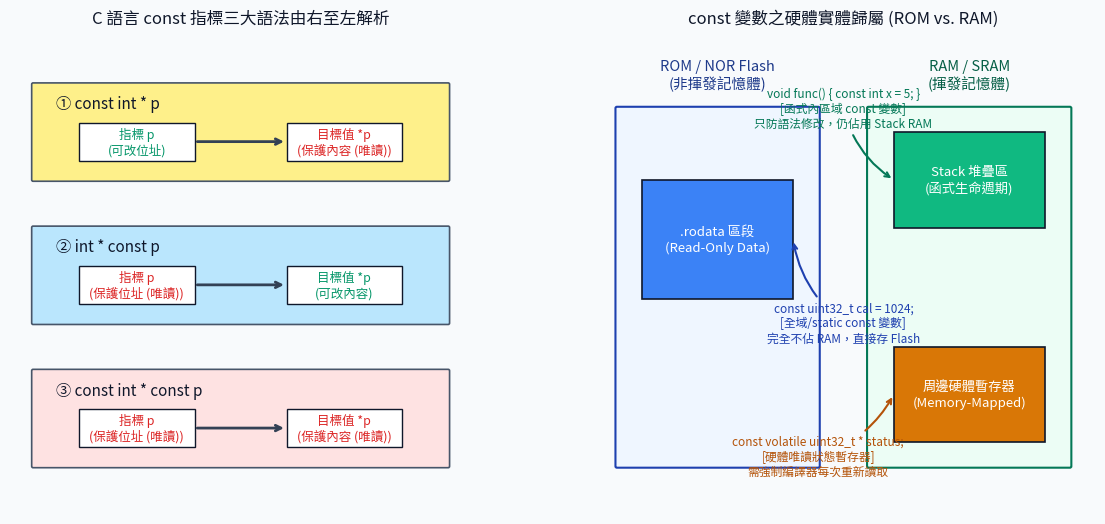

In [51]:
# 【第五題模擬 5.3】C 語言 const 指標操作語意與 ROM / RAM 記憶體歸屬視覺化模擬
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import urllib.request
import os
import matplotlib.font_manager as fm

# 自動下載並設定繁體中文字型
font_path = "NotoSansCJKtc-Regular.otf"
if not os.path.exists(font_path):
    font_url = "https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf"
    urllib.request.urlretrieve(font_url, font_path)
fm.fontManager.addfont(font_path)
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK TC', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

print("=" * 95)
print("【Q5 模擬一】C 語言三大 const 指標修飾語法行為模擬 (編譯期檢查)")
print("-" * 95)
print("1. [const int *p] (指向常數的指標)")
print("   -> 狀態: p 可以改指別人，但不能透過 *p 改值。 (保護所指內容)")
print("   -> 範例: p = &another_val; (✅ OK) | *p = 30; (❌ 編譯錯誤 Error: assignment of read-only location)")
print("2. [int * const p] (常數指標)")
print("   -> 狀態: p 綁定死位址，但可以透過 *p 改值。 (保護指標本身)")
print("   -> 範例: p = &another_val; (❌ 編譯錯誤 Error: assignment of read-only variable) | *p = 30; (✅ OK)")
print("3. [const int * const p] (指向常數的常數指標)")
print("   -> 狀態: 位址與內容皆唯讀被鎖死。 (雙重保護)")
print("   -> 範例: p = &another; (❌) | *p = 30; (❌)")
print("=" * 95)

# 建立畫布
fig_q5 = plt.figure(figsize=(14.0, 6.2), facecolor='#F8FAFC')
gs5 = fig_q5.add_gridspec(1, 2, width_ratios=[1.1, 1.2], wspace=0.25)

# --- 左圖：const 指標語意圖 ---
ax_ptr = fig_q5.add_subplot(gs5[0])
ax_ptr.set_facecolor('#FFFFFF')
ax_ptr.set_xlim(0, 100)
ax_ptr.set_ylim(0, 100)
ax_ptr.axis('off')
ax_ptr.set_title("C 語言 const 指標三大語法由右至左解析", fontsize=12, fontweight='bold', color='#0F172A', pad=10)

# 繪製三個比較區塊
ptr_blocks = [
    (70, "① const int * p", "保護內容 (唯讀)", "可改位址", "#FEF08A", "#DC2626", "#059669"),
    (40, "② int * const p", "可改內容", "保護位址 (唯讀)", "#BAE6FD", "#059669", "#DC2626"),
    (10, "③ const int * const p", "保護內容 (唯讀)", "保護位址 (唯讀)", "#FEE2E2", "#DC2626", "#DC2626")
]

for y_pos, title, val_stat, addr_stat, bg_col, val_col, addr_col in ptr_blocks:
    rect = patches.FancyBboxPatch((5, y_pos), 90, 20, boxstyle="round,pad=0.3", facecolor=bg_col, edgecolor="#475569", linewidth=1.2)
    ax_ptr.add_patch(rect)
    ax_ptr.text(10, y_pos + 15, title, fontsize=11, fontweight='bold', color='#0F172A')

    # 指標框
    p_rect = patches.Rectangle((15, y_pos + 4), 25, 8, facecolor="#FFFFFF", edgecolor="#0F172A", linewidth=1)
    ax_ptr.add_patch(p_rect)
    ax_ptr.text(27.5, y_pos + 8, f"指標 p\n({addr_stat})", ha='center', va='center', fontsize=9, fontweight='bold', color=addr_col)

    # 目標值框
    v_rect = patches.Rectangle((60, y_pos + 4), 25, 8, facecolor="#FFFFFF", edgecolor="#0F172A", linewidth=1)
    ax_ptr.add_patch(v_rect)
    ax_ptr.text(72.5, y_pos + 8, f"目標值 *p\n({val_stat})", ha='center', va='center', fontsize=9, fontweight='bold', color=val_col)

    # 箭頭
    ax_ptr.annotate("", xy=(60, y_pos + 8), xytext=(40, y_pos + 8), arrowprops=dict(arrowstyle="->", color="#334155", lw=2))

# --- 右圖：ROM vs RAM 記憶體歸屬圖 ---
ax_mem = fig_q5.add_subplot(gs5[1])
ax_mem.set_facecolor('#FFFFFF')
ax_mem.set_xlim(0, 100)
ax_mem.set_ylim(0, 100)
ax_mem.axis('off')
ax_mem.set_title("const 變數之硬體實體歸屬 (ROM vs. RAM)", fontsize=12, fontweight='bold', color='#0F172A', pad=10)

# ROM 區塊
ax_mem.text(25, 92, "ROM / NOR Flash\n(非揮發記憶體)", ha='center', va='center', fontsize=10.5, fontweight='bold', color='#1E3A8A')
rom_rect = patches.FancyBboxPatch((5, 10), 40, 75, boxstyle="round,pad=0.3", facecolor="#EFF6FF", edgecolor="#1E40AF", linewidth=1.5)
ax_mem.add_patch(rom_rect)

rodata_rect = patches.Rectangle((10, 45), 30, 25, facecolor="#3B82F6", edgecolor="#0F172A", linewidth=1.2)
ax_mem.add_patch(rodata_rect)
ax_mem.text(25, 57.5, ".rodata 區段\n(Read-Only Data)", ha='center', va='center', fontsize=9.5, fontweight='bold', color='white')

# RAM 區塊
ax_mem.text(75, 92, "RAM / SRAM\n(揮發記憶體)", ha='center', va='center', fontsize=10.5, fontweight='bold', color='#065F46')
ram_rect = patches.FancyBboxPatch((55, 10), 40, 75, boxstyle="round,pad=0.3", facecolor="#ECFDF5", edgecolor="#047857", linewidth=1.5)
ax_mem.add_patch(ram_rect)

stack_rect = patches.Rectangle((60, 60), 30, 20, facecolor="#10B981", edgecolor="#0F172A", linewidth=1.2)
ax_mem.add_patch(stack_rect)
ax_mem.text(75, 70, "Stack 堆疊區\n(函式生命週期)", ha='center', va='center', fontsize=9.5, fontweight='bold', color='white')

mmio_rect = patches.Rectangle((60, 15), 30, 20, facecolor="#D97706", edgecolor="#0F172A", linewidth=1.2)
ax_mem.add_patch(mmio_rect)
ax_mem.text(75, 25, "周邊硬體暫存器\n(Memory-Mapped)", ha='center', va='center', fontsize=9.5, fontweight='bold', color='white')

# 變數映射連線與說明
ax_mem.annotate("const uint32_t cal = 1024;\n[全域/static const 變數]\n完全不佔 RAM，直接存 Flash", xy=(40, 57.5), xytext=(50, 40),
                ha='center', va='center', fontsize=8.5, fontweight='bold', color='#1E40AF',
                arrowprops=dict(arrowstyle="->", color="#1E40AF", lw=1.5, connectionstyle="arc3,rad=-0.2"))

ax_mem.annotate("void func() { const int x = 5; }\n[函式內區域 const 變數]\n只防語法修改，仍佔用 Stack RAM", xy=(60, 70), xytext=(50, 85),
                ha='center', va='center', fontsize=8.5, fontweight='bold', color='#047857',
                arrowprops=dict(arrowstyle="->", color="#047857", lw=1.5, connectionstyle="arc3,rad=0.2"))

ax_mem.annotate("const volatile uint32_t * status;\n[硬體唯讀狀態暫存器]\n需強制編譯器每次重新讀取", xy=(60, 25), xytext=(45, 12),
                ha='center', va='center', fontsize=8.5, fontweight='bold', color='#B45309',
                arrowprops=dict(arrowstyle="->", color="#B45309", lw=1.5, connectionstyle="arc3,rad=0.2"))

# plt.tight_layout() # 移除以避免 UserWarning
plt.show()


---

# 【第六題】06 / CIRCUIT ANALYSIS：根據某一點的電流計算電壓？

> **對應簡報頁次**：Slide 7 ~ 8 (`06 / CIRCUIT ANALYSIS — 由電流反推節點電壓與 MCCCII 主動濾波器導納矩陣`)
> **本題參考文獻**：
> 1. Adel S. Sedra, Kenneth C. Smith, [《Microelectronic Circuits (8th Edition)》](https://www.oup.com.au/books/higher-education/science/9780190853464-sedra-and-smith-microelectronic-circuits-8e) (電子學經典教材)
> 2. Charles K. Alexander, Matthew N. O. Sadiku, [《Fundamentals of Electric Circuits (7th Edition)》](https://www.mheducation.com/highered/product/1260226409.html) (節點電壓法與 KCL/KVL 矩陣分析標準學理)

---

## 6.1 理論基礎：克希荷夫電流定律 (KCL) 與並聯等效電路分析

### (1) 基礎物理定律與 KCL 節點電壓法
* **克希荷夫電流定律 (Kirchhoff's Current Law, KCL)**：電荷守恆定律的直接體現。在電路中任一電器節點 (Node) 上，**流入該節點的電流總和必等於流出該節點的電流總和**：
  $$\sum I_{in} = \sum I_{out}$$
* **並聯分流網路理論**：若已知一注入電流源 $I_{in}$ 流入節點 $V_{node}$，該節點經由兩條並聯支路（分流電阻分別為 $R_1$ 與 $R_2$）通往系統接地點 (GND, 0V)，依據 KCL：
  $$I_{in} = I_{R1} + I_{R2} = \frac{V_{node} - 0}{R_1} + \frac{V_{node} - 0}{R_2}$$
* 整理通分後，即可求得節點電壓 $V_{node}$ 與輸入電流的對應物理量關係。此即為電阻並聯等效阻抗 $R_{eq}$ 的由來：
  $$V_{node} = I_{in} \times (R_1 \parallel R_2) = I_{in} \times \frac{R_1 R_2}{R_1 + R_2}$$

### (2) 韌體演算法與驗證的物理數學映射
在微控制器（MCU）周邊 ADC 電壓取樣、PMIC 分壓或電流感測電阻網路（Telemetry）的設計中，系統無法直接測量「阻抗」，而是藉由採集電壓，透過此等效公式於韌體中即時反算出流入的電流值。這也是進行硬體迴路模擬時最重要的實體數學映射。

## 6.2 Python 模擬實戰：SymPy KCL 符號公式推導、NumPy 電流-電壓響應曲線與無損電路原理圖

In [52]:
# 【第六題模擬 6.2a】使用 SymPy 進行 KCL 節點方程式符號代數求解與並聯阻抗驗證
import sympy as sp

# 宣告 SymPy 符號變數
V_node, I_in, R1, R2 = sp.symbols('V_node I_in R1 R2')

# 建立 KCL 方程式：流入 = 流出
kcl_equation = sp.Eq(I_in, V_node/R1 + V_node/R2)

# 自動解出 V_node 的符號代數表達式
voltage_solution = sp.solve(kcl_equation, V_node)

print("=" * 86)
print("【Q6 模擬一】使用 SymPy 進行 KCL 節點方程式符號代數求解結果")
print("-" * 86)
print("給定之 KCL 方程式: I_in = V_node / R1 + V_node / R2")
print(f"自動解出之 V_node 代數公式解 = {voltage_solution[0]}")
print("公式化簡結果 (並聯等效阻抗公式):", sp.simplify(voltage_solution[0]))
print("=" * 86)

【Q6 模擬一】使用 SymPy 進行 KCL 節點方程式符號代數求解結果
--------------------------------------------------------------------------------------
給定之 KCL 方程式: I_in = V_node / R1 + V_node / R2
自動解出之 V_node 代數公式解 = I_in*R1*R2/(R1 + R2)
公式化簡結果 (並聯等效阻抗公式): I_in*R1*R2/(R1 + R2)


【Q6 模擬二】動態數值代入與硬體驗證：KCL 理想電壓 vs. ADC 實際量測電壓 (I_in = 1A ~ 10A)
設定分流電阻: R1 = 10.0 Ohm, R2 = 20.0 Ohm -> 等效並聯阻抗 = 6.6667 Ohm
-----------------------------------------------------------------------------------------------
  - 當注入 I_in = 1.0 A 時  -> 理想 V_node = 6.67 V | 實測 V_node = 7.11 V
  - 當注入 I_in = 5.0 A 時  -> 理想 V_node = 33.61 V | 實測 V_node = 34.93 V
  - 當注入 I_in = 10.0 A 時 -> 理想 V_node = 66.67 V | 實測 V_node = 70.26 V (出現明顯熱漂移)


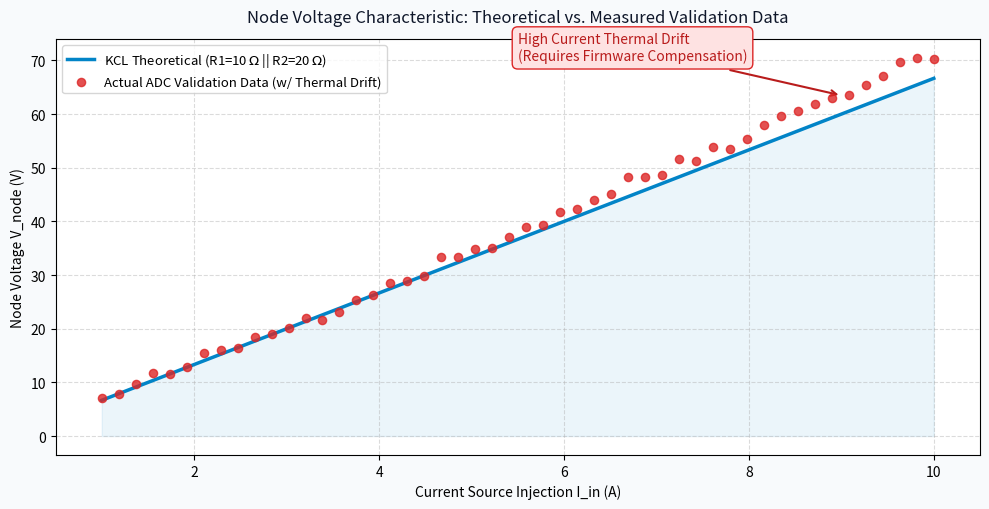

In [53]:
# 【第六題模擬 6.2b】加入硬體驗證實測數據：KCL 理論值 vs. ADC 實際量測值 (包含雜訊與熱漂移)
import numpy as np
import matplotlib.pyplot as plt

def calculate_node_voltage(i_in, r1, r2):
    # 根據並聯等效電阻公式：V = I * (R1 || R2)
    eq_resistance = (r1 * r2) / (r1 + r2)
    return i_in * eq_resistance

# 設定模擬參數：電流源從 1A 變動至 10A (50個採樣點)
current_inputs = np.linspace(1, 10, 50)
r1_val, r2_val = 10.0, 20.0

# 1. 理論電壓值 (KCL 理想模型)
voltage_outputs_ideal = calculate_node_voltage(current_inputs, r1_val, r2_val)

# 2. 模擬硬體實際驗證數據 (加入 ADC 取樣雜訊與大電流熱漂移誤差)
# 熱漂移效應：電流越大，電阻發熱導致阻值微幅上升，產生非線性誤差
np.random.seed(42)
thermal_drift = 0.05 * (current_inputs ** 2)  # 非線性熱漂移
adc_noise = np.random.normal(0, 0.8, size=len(current_inputs)) # ADC 白雜訊
voltage_outputs_measured = voltage_outputs_ideal + thermal_drift + adc_noise

print("=" * 95)
print("【Q6 模擬二】動態數值代入與硬體驗證：KCL 理想電壓 vs. ADC 實際量測電壓 (I_in = 1A ~ 10A)")
print(f"設定分流電阻: R1 = {r1_val} Ohm, R2 = {r2_val} Ohm -> 等效並聯阻抗 = {(r1_val*r2_val)/(r1_val+r2_val):.4f} Ohm")
print("-" * 95)
print(f"  - 當注入 I_in = 1.0 A 時  -> 理想 V_node = {voltage_outputs_ideal[0]:.2f} V | 實測 V_node = {voltage_outputs_measured[0]:.2f} V")
print(f"  - 當注入 I_in = 5.0 A 時  -> 理想 V_node = {voltage_outputs_ideal[22]:.2f} V | 實測 V_node = {voltage_outputs_measured[22]:.2f} V")
print(f"  - 當注入 I_in = 10.0 A 時 -> 理想 V_node = {voltage_outputs_ideal[-1]:.2f} V | 實測 V_node = {voltage_outputs_measured[-1]:.2f} V (出現明顯熱漂移)")
print("=" * 95)

# 繪製 V-I 響應特性曲線 (理想 vs 實測)
fig6_v = plt.figure(figsize=(10.0, 5.2), facecolor='#F8FAFC')
ax_v = fig6_v.add_subplot(1, 1, 1)
ax_v.set_facecolor('#FFFFFF')

# 繪製理論曲線
ax_v.plot(current_inputs, voltage_outputs_ideal, label=r'KCL Theoretical (R1=10$\,\Omega$ || R2=20$\,\Omega$)', color='#0284C7', linewidth=2.5, zorder=3)
ax_v.fill_between(current_inputs, voltage_outputs_ideal, color='#0284C7', alpha=0.08)

# 繪製實際驗證數據散佈圖
ax_v.scatter(current_inputs, voltage_outputs_measured, label='Actual ADC Validation Data (w/ Thermal Drift)', color='#DC2626', s=35, alpha=0.8, zorder=4)

# 標記高電流時的誤差區域
ax_v.annotate("High Current Thermal Drift\n(Requires Firmware Compensation)",
              xy=(9.0, voltage_outputs_measured[-6]), xytext=(5.5, 70),
              arrowprops=dict(arrowstyle="->", color="#B91C1C", lw=1.5),
              fontsize=10, fontweight='bold', color='#B91C1C',
              bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEE2E2", edgecolor="#DC2626"))

ax_v.set_title("Node Voltage Characteristic: Theoretical vs. Measured Validation Data", fontsize=12, fontweight='bold', color='#0F172A', pad=12)
ax_v.set_xlabel("Current Source Injection I_in (A)", fontsize=10, fontweight='bold')
ax_v.set_ylabel("Node Voltage V_node (V)", fontsize=10, fontweight='bold')
ax_v.set_xlim(0.5, 10.5)
ax_v.grid(True, linestyle='--', alpha=0.45)
ax_v.legend(loc='upper left', fontsize=9.5)
plt.tight_layout()
plt.show()


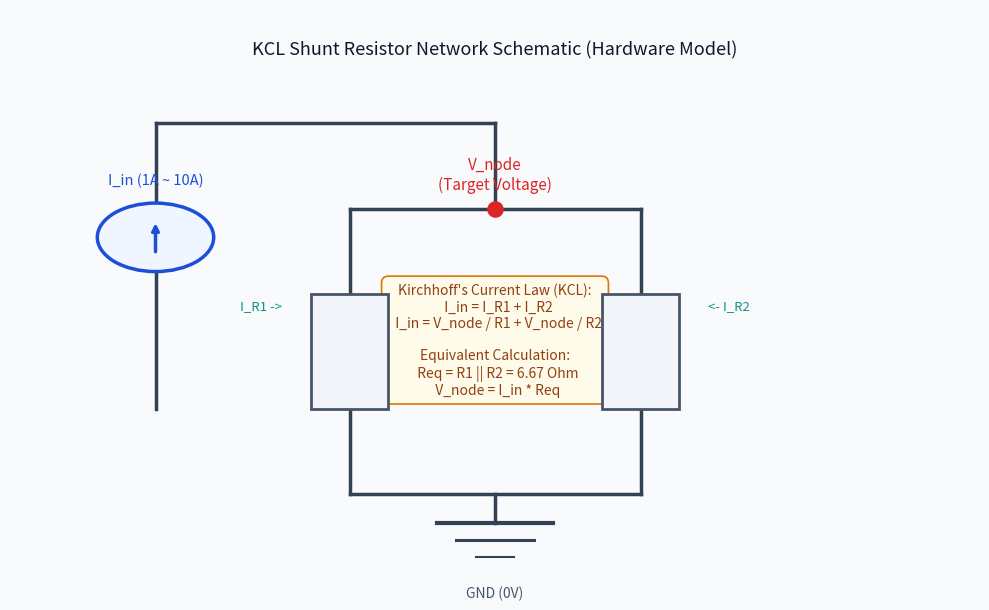

In [54]:
# 【第六題模擬 6.2c】繪製實體硬體電路原理圖 (使用純英文 Label 防止作業系統字型缺字導致空白方格)
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig_circ = plt.figure(figsize=(10, 6.2), facecolor='#F8FAFC')
ax_c = fig_circ.add_subplot(1, 1, 1)
ax_c.set_facecolor('#FFFFFF')
ax_c.set_xlim(0, 100)
ax_c.set_ylim(0, 100)
ax_c.axis('off')

# 1. 電路原理圖標題
ax_c.text(50, 93, "KCL Shunt Resistor Network Schematic (Hardware Model)", ha='center', va='center', fontsize=13, fontweight='bold', color='#0F172A')

# 2. 繪製輸入電流源 (Current Source)
circle_src = plt.Circle((15, 60), 6, facecolor='#EFF6FF', edgecolor='#1D4ED8', linewidth=2.5, zorder=3)
ax_c.add_patch(circle_src)
# 電流源箭頭
ax_c.annotate("", xy=(15, 63), xytext=(15, 57), arrowprops=dict(arrowstyle="->", color="#1D4ED8", lw=2.5))
ax_c.text(15, 70, "I_in (1A ~ 10A)", ha='center', va='center', fontsize=10.5, fontweight='bold', color='#1D4ED8')

# 3. 導線連接線路 (Wires)
ax_c.plot([15, 15], [54, 30], color='#334155', linewidth=2.5) # 下端導線
ax_c.plot([15, 15], [66, 80], color='#334155', linewidth=2.5) # 上端導線
ax_c.plot([15, 50], [80, 80], color='#334155', linewidth=2.5) # 橫向拉至節點上方
ax_c.plot([50, 50], [80, 65], color='#334155', linewidth=2.5) # 垂直拉至節點

# 節點分流導線
ax_c.plot([50, 35], [65, 65], color='#334155', linewidth=2.5)
ax_c.plot([50, 65], [65, 65], color='#334155', linewidth=2.5)
ax_c.plot([35, 35], [65, 50], color='#334155', linewidth=2.5)
ax_c.plot([65, 65], [65, 50], color='#334155', linewidth=2.5)

# 電阻下端拉回 GND 的導線
ax_c.plot([35, 35], [30, 15], color='#334155', linewidth=2.5)
ax_c.plot([65, 65], [30, 15], color='#334155', linewidth=2.5)
ax_c.plot([35, 65], [15, 15], color='#334155', linewidth=2.5)
ax_c.plot([50, 50], [15, 10], color='#334155', linewidth=2.5)

# 4. 節點與電壓標記 (Node V_node)
ax_c.scatter([50], [65], color='#DC2626', s=120, zorder=5)
ax_c.text(50, 71, "V_node\n(Target Voltage)", ha='center', va='center', fontsize=11, fontweight='bold', color='#DC2626')

# 5. 繪製分流電阻 R1 & R2
# R1 電阻體
rect_r1 = patches.Rectangle((31, 30), 8, 20, facecolor='#F1F5F9', edgecolor='#475569', linewidth=2.0, zorder=4)
ax_c.add_patch(rect_r1)
ax_c.text(35, 40, "R1\n10 Ohm", ha='center', va='center', fontsize=10, fontweight='bold', color='#1E293B')
ax_c.text(28, 48, "I_R1 ->", ha='right', va='center', fontsize=9.5, fontweight='bold', color='#0D9488')

# R2 電阻體
rect_r2 = patches.Rectangle((61, 30), 8, 20, facecolor='#F1F5F9', edgecolor='#475569', linewidth=2.0, zorder=4)
ax_c.add_patch(rect_r2)
ax_c.text(65, 40, "R2\n20 Ohm", ha='center', va='center', fontsize=10, fontweight='bold', color='#1E293B')
ax_c.text(72, 48, "<- I_R2", ha='left', va='center', fontsize=9.5, fontweight='bold', color='#0D9488')

# 6. 接地標記 (Standard Ground Symbol)
ax_c.plot([44, 56], [10, 10], color='#334155', linewidth=3.0)
ax_c.plot([46, 54], [7, 7], color='#334155', linewidth=2.2)
ax_c.plot([48, 52], [4, 4], color='#334155', linewidth=1.5)
ax_c.text(50, -1, "GND (0V)", ha='center', va='top', fontsize=10, fontweight='bold', color='#475569')

# 7. 硬體分析數學公式對照框
box_style = dict(boxstyle="round,pad=0.5", facecolor="#FFFBEB", edgecolor="#D97706", linewidth=1.2)
formula_text = (
    "Kirchhoff's Current Law (KCL):\n"
    "  I_in = I_R1 + I_R2\n"
    "  I_in = V_node / R1 + V_node / R2\n\n"
    "Equivalent Calculation:\n"
    "  Req = R1 || R2 = 6.67 Ohm\n"
    "  V_node = I_in * Req"
)
ax_c.text(50, 42, formula_text, ha='center', va='center', fontsize=10, fontweight='bold', color='#92400E', bbox=box_style)

plt.tight_layout()
plt.show()

## 6.3 韌體驗證實務：高邊/低邊電流監控 (Telemetry) 與 NTC 溫度漂移非線性補償演算法

### 💡 (1) 考點深度解析：從硬體 KCL 公式到韌體數位模型
面試官提問 KCL 電路目的並非只考察基本分流計算，更在於了解工程師是否明白**「如何將物理現象轉換為微控制器的數值補償演算法」**：
* **離散取樣誤差**：硬體 ADC 存在解析度上限（如 12-bit ADC 對應 $0\text{ V}$ 至 $3.3\text{ V}$ 的 $2^{12} = 4096$ 刻度）。若分流電阻因大電流發熱導致阻值偏離，韌體中若只套用固定數值 $6.67\ \Omega$，將會計算出錯誤的電流 Telemetry 讀數。
* **軟硬體整合映射**：在嵌入式環境中，MCU 無法直接用「公式」運算，而是需要將阻抗與係數矩陣離散化或代數化後，寫入韌體暫存器執行。

### 🛠️ (2) 韌體驗證與實務開發連結：
* **高邊與低邊電流監控 (High-Side vs. Low-Side Sensing)**：
  在伺服器高規電源供應器（PSU / PMBus）驗證中，通常會於線路中串接超低阻值（例如 $0.001\ \Omega \sim 0.01\ \Omega$）的精密分流電阻，配合運算放大器放大其壓降。驗證時需注意主機高共模電壓帶來的雜訊，並進行偏置電壓（Offset Voltage）補償。
* **溫度與非線性電阻補償 (NTC Thermistor Lookup)**：
  在電池包管理系統 (BMS) 或發熱元件旁，會使用 NTC 熱敏電阻與固定電阻串聯分壓。韌體工程師必須透過 ADC 讀取節點電壓 $V_{node}$，反推熱敏電阻值 $R_{NTC}$，再查表 (LUT) 或使用 Steinhart-Hart 公式求得當前攝氏溫度，動態補償分流電阻的非線性溫度漂移（TCR），確保全溫度範圍內量測精準。